# Flood Susceptibility Mapping: Semarang-Demak Only

**Study case:** Kota Semarang dan Kabupaten Demak.
**Jenis analisis:** supervised binary classification.  
**Framing artikel:** comparative explainable ensemble learning for flood susceptibility mapping.  
**Output standar artikel:** model metrics, ROC curve, confusion matrix semua model, feature importance, SHAP, peta label banjir, peta prediktor, dan peta kerawanan banjir.

Keterangan:
1. BNPB/BPBD/berita resmi dipakai untuk justifikasi periode kejadian banjir.
2. Sentinel-1 SAR digunakan untuk membuat proxy flood inventory atau label banjir 1/0.
3. Prediktor geospasial multi-sumber diambil dari GEE.
4. Model ensemble dibandingkan di Python: Random Forest, ExtraTrees, Gradient Boosting, XGBoost, LightGBM, CatBoost, dan Stacking.
5. Model terbaik dievaluasi dan dijelaskan dengan SHAP.
6. Peta raster probabilitas dibuat di GEE dengan Random Forest sebagai model operasional spasial.
7. Seluruh visual utama dibuat dalam format PNG/HTML agar dapat langsung dimasukkan ke artikel.

## 0. Dataset yang dipakai

- Sentinel-1 GRD: `COPERNICUS/S1_GRD` untuk label banjir berbasis perubahan backscatter.
- Sentinel-2 Surface Reflectance: `COPERNICUS/S2_SR_HARMONIZED` untuk NDVI, NDWI, MNDWI, dan NDBI.
- SRTM DEM 30 m: `USGS/SRTMGL1_003` untuk elevation, slope, dan aspect.
- CHIRPS Daily: `UCSB-CHG/CHIRPS/DAILY` untuk curah hujan 7 dan 30 hari.
- ESA WorldCover 2021: `ESA/WorldCover/v200` untuk landcover.
- MERIT Hydro: `MERIT/Hydro/v1_0_1` untuk HAND, upstream drainage area, river width, dan aproksimasi jaringan sungai.
- JRC Global Surface Water: `JRC/GSW1_4/GlobalSurfaceWater` untuk permanent water mask dan distance to permanent water.


## 1. Import library

In [ ]:
!pip -q install earthengine-api geemap shap xgboost lightgbm catboost scikit-learn pandas numpy matplotlib joblib pillow requests


In [ ]:
import os
import math
import time
import warnings
warnings.filterwarnings('ignore')

from google.colab import drive
drive.mount('/content/drive')

OUTPUT_DIR = '/content/drive/MyDrive/GEE_Flood_Susceptibility_Semarang_Demak/PDF'
os.makedirs(OUTPUT_DIR, exist_ok=True)

import ee
import geemap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import requests
from PIL import Image
from io import BytesIO

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report,
    ConfusionMatrixDisplay
)
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.inspection import permutation_importance
import joblib

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
import shap

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)


Mounted at /content/drive


## 2. Autentikasi Google Earth Engine

In [ ]:
# =========================================================
# Autentikasi Google Earth Engine.
# Cara utama: Service Account key JSON (TANPA login popup setiap run).
#   1. Buat key: https://console.cloud.google.com/iam-admin/serviceaccounts
#      -> pilih project -> Keys -> Add key -> JSON.
#   2. Beri role 'Service Usage Consumer' dan daftarkan akun Earth Engine
#      (https://code.earthengine.google.com/register) dengan project yang sama.
#   3. Simpan file JSON di Drive folder
#      GEE_Flood_Susceptibility_Semarang_Demak/  dengan nama gee-service-account.json
#      (atau upload ke /content/, atau set env GOOGLE_APPLICATION_CREDENTIALS,
#       atau di Kaggle simpan isi JSON sebagai Secret bernama GEE_SERVICE_ACCOUNT_JSON).
# Jika key tidak ditemukan, fallback ke ee.Authenticate() interaktif.
# =========================================================
EE_PROJECT = "ee-irfan-banjir-2026"  # nama project GEE

import os as _os, json as _json, base64 as _b64

_service_email, _key_path = None, None

def _try_use_key(path):
    global _service_email, _key_path
    try:
        with open(path, 'r', encoding='utf-8') as fh:
            info = _json.load(fh)
        if info.get('type') != 'service_account':
            print('Bukan service account key:', path)
            return False
        creds = ee.ServiceAccountCredentials(info['client_email'], path)
        ee.Initialize(credentials=creds, project=(info.get('project_id') or EE_PROJECT or None))
        _service_email, _key_path = info['client_email'], path
        return True
    except Exception as e:
        print('Key gagal dipakai (%s): %s' % (path, e))
        return False

_key_candidates = [
    '/content/drive/MyDrive/GEE_Flood_Susceptibility_Semarang_Demak/gee-service-account.json',
    '/content/gee-service-account.json',
    '/kaggle/working/gee-service-account.json',
    'gee-service-account.json',
]
if _os.environ.get('GOOGLE_APPLICATION_CREDENTIALS'):
    _key_candidates.insert(0, _os.environ['GOOGLE_APPLICATION_CREDENTIALS'])

# Kaggle Secrets (isi JSON sebagai string)
try:
    from kaggle_secrets import UserSecretsClient
    _sec = UserSecretsClient().get_secret("GEE_SERVICE_ACCOUNT_JSON")
    if _sec and 'service_account' in _sec:
        try:
            _sec = _b64.b64decode(_sec).decode('utf-8')
        except Exception:
            pass
        _p = '/kaggle/working/gee-service-account.json'
        with open(_p, 'w', encoding='utf-8') as fh:
            fh.write(_sec)
        _key_candidates.insert(0, _p)
except Exception:
    pass

_initialized = False
for _p in _key_candidates:
    if _p and _os.path.exists(_p):
        _initialized = _try_use_key(_p)
        if _initialized:
            break

if not _initialized:
    print('Service account key tidak ditemukan/gagal. Fallback ke login interaktif...')
    ee.Authenticate()
    ee.Initialize(project=EE_PROJECT) if EE_PROJECT else ee.Initialize()

if _service_email:
    print('GEE siap via service account:', _service_email)
    print('Key file:', _key_path)
else:
    print('GEE siap via login interaktif.')


## 3. Parameter wilayah dan tanggal

- `BEFORE_START` sampai `BEFORE_END`: periode sebelum banjir.
- `AFTER_START` sampai `AFTER_END`: periode saat/sesudah banjir.
- `S2_START` sampai `S2_END`: periode Sentinel-2 untuk prediktor permukaan. Sebaiknya bukan saat banjir langsung agar tidak terjadi *data leakage*.

In [ ]:
# =========================================================
# PARAMETER WILAYAH
# =========================================================
# Pilihan:
# 1. 'SEMDEMAK_ONLY'       = hanya Kota Semarang dan Kabupaten Demak.
# 2. 'SEMDEMAK_SURROUNDING'= kotak Semarang-Demak dan sekitarnya seperti output orisinal.
ROI_MODE = 'SEMDEMAK_ONLY'

# Batas kotak output orisinal, dipakai hanya jika ROI_MODE = 'SEMDEMAK_SURROUNDING'.
SURROUNDING_RECTANGLE = [109.95, -7.45, 111.05, -6.65]  # [lon_min, lat_min, lon_max, lat_max]

# Untuk ROI administrasi, pakai FAO GAUL level 2.
# Catatan: nama ADM2 di GEE bisa berbeda. Cell ini akan menampilkan nama wilayah yang terpilih.
wilayah_indonesia = ee.FeatureCollection('FAO/GAUL/2015/level2').filter(ee.Filter.eq('ADM0_NAME', 'Indonesia'))

if ROI_MODE == 'SEMDEMAK_ONLY':
    # Prioritas: Kota Semarang + Demak.
    wanted_names_primary = ['Kota Semarang', 'Demak']
    semarang_demak = wilayah_indonesia.filter(ee.Filter.inList('ADM2_NAME', wanted_names_primary))

    # Fallback jika database GAUL memakai nama 'Semarang' untuk kota/kabupaten.
    if semarang_demak.size().getInfo() < 2:
        print('Peringatan: filter primary belum menemukan dua wilayah. Mencoba fallback nama Semarang + Demak.')
        wanted_names_fallback = ['Semarang', 'Demak']
        semarang_demak = wilayah_indonesia.filter(ee.Filter.inList('ADM2_NAME', wanted_names_fallback))

    selected_names = semarang_demak.aggregate_array('ADM2_NAME').getInfo()
    print('ROI_MODE:', ROI_MODE)
    print('Wilayah administratif yang terpilih:', selected_names)
    print('Jumlah fitur administratif:', semarang_demak.size().getInfo())
    roi = semarang_demak.geometry()

elif ROI_MODE == 'SEMDEMAK_SURROUNDING':
    print('ROI_MODE:', ROI_MODE)
    print('Menggunakan rectangle Semarang-Demak dan sekitarnya:', SURROUNDING_RECTANGLE)
    roi = ee.Geometry.Rectangle(SURROUNDING_RECTANGLE)
    semarang_demak = ee.FeatureCollection([ee.Feature(roi, {'ADM2_NAME': 'Semarang-Demak surrounding rectangle'})])
else:
    raise ValueError("ROI_MODE harus 'SEMDEMAK_ONLY' atau 'SEMDEMAK_SURROUNDING'.")

# Default contoh kejadian banjir 2024. Ubah sesuai bukti BNPB/BPBD/berita.
# Kejadian banjir Demak II / banjir Jawa Tengah Maret 2024.
BEFORE_START = '2024-02-25'
BEFORE_END   = '2024-03-12'
AFTER_START  = '2024-03-15'
AFTER_END    = '2024-03-31'

# Komposit Sentinel-2 untuk prediktor permukaan.
# Gunakan periode normal/pra-kejadian agar tidak terjadi data leakage.
S2_START = '2023-06-01'
S2_END   = '2023-10-31'

# Parameter label banjir Sentinel-1.
S1_POLARIZATION = 'VH'
S1_RATIO_THRESHOLD = 1.25
AFTER_DB_THRESHOLD = -18
SLOPE_MAX_FOR_FLOOD = 5
MIN_CONNECTED_PIXELS = 8

# Sampling.
# TARGET maksimum per kelas. Untuk SEMDEMAK_ONLY, jumlah flood pixel bisa hanya sekitar 1630.
# Jika AUTO_BALANCE_SAMPLE=True, jumlah sampel per kelas otomatis diambil sebagai minimum dari:
# target, jumlah flood pixel tersedia, dan jumlah non-flood pixel tersedia.
SAMPLE_PER_CLASS_TARGET = 3000
AUTO_BALANCE_SAMPLE = True
SAMPLE_SCALE = 30
TILE_SCALE = 8

# Parameter jaringan sungai untuk dist_river.
RIVER_UPA_THRESHOLD = 10  # km^2

# Center peta default.
MAP_CENTER = [-7.05, 110.45]
MAP_ZOOM = 10


ROI_MODE: SEMDEMAK_ONLY
Wilayah administratif yang terpilih: ['Demak', 'Kota Semarang']
Jumlah fitur administratif: 2


## 4. Fungsi bantu Earth Engine

In [ ]:
def db_to_power(img_db):
    # Konversi Sentinel-1 dB ke power scale.
    return ee.Image(10).pow(img_db.divide(10))


def get_s1_median(start, end, roi, orbit_pass=None):
    # Ambil median Sentinel-1 GRD VV/VH untuk periode tertentu.
    col = (ee.ImageCollection('COPERNICUS/S1_GRD')
           .filterBounds(roi)
           .filterDate(start, end)
           .filter(ee.Filter.eq('instrumentMode', 'IW'))
           .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VV'))
           .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VH'))
           .select(['VV', 'VH']))
    if orbit_pass is not None:
        col = col.filter(ee.Filter.eq('orbitProperties_pass', orbit_pass))
    return col.median().clip(roi)


def mask_s2_clouds(img):
    # Mask awan sederhana Sentinel-2 SR memakai QA60.
    qa = img.select('QA60')
    cloud_bit_mask = 1 << 10
    cirrus_bit_mask = 1 << 11
    mask = qa.bitwiseAnd(cloud_bit_mask).eq(0).And(
        qa.bitwiseAnd(cirrus_bit_mask).eq(0)
    )
    return img.updateMask(mask).divide(10000)


def add_lon_lat(feature):
    coords = feature.geometry().coordinates()
    return feature.set({'lon': coords.get(0), 'lat': coords.get(1)})


def safe_add_legend(MapObj, title, legend_dict):
    try:
        MapObj.add_legend(title=title, legend_dict=legend_dict)
    except Exception as e:
        print(f'Legend tidak bisa ditambahkan otomatis: {title} | {e}')


def safe_add_layer_control(MapObj):
    try:
        MapObj.add_layer_control()
    except Exception:
        try:
            MapObj.addLayerControl()
        except Exception:
            pass


def center_map_on_roi(MapObj, roi, zoom=10):
    try:
        MapObj.centerObject(roi, zoom)
    except Exception:
        MapObj.setCenter(MAP_CENTER[1], MAP_CENTER[0], zoom)


def save_map_html(MapObj, filename):
    path = os.path.join(OUTPUT_DIR, filename)
    try:
        MapObj.to_html(path)
        print('Map HTML tersimpan:', path)
    except Exception as e:
        print('Map HTML gagal disimpan:', e)
    return path


def ee_thumb(image, vis_params, region, dimensions=1600, outline=True, filename=None,
             max_retries=4, base_delay=5):
    """Ambil thumbnail PNG dari ee.Image untuk figure statis matplotlib.

    Menyertakan retry dengan exponential backoff untuk menangani error 503
    (Service Unavailable, bersifat transient di sisi server Earth Engine) dan
    penurunan dimensi otomatis jika terjadi error 400 User memory limit exceeded
    (biasanya muncul pada layer hasil komputasi berat seperti prob_map,
    risk_class, atau cost-distance seperti dist_river dan dist_perm_water).
    """
    vis_img = image.visualize(**vis_params)
    if outline:
        outline_img = ee.Image().byte().paint(region, 1, 2).visualize(palette=['000000'])
        vis_img = vis_img.blend(outline_img)

    current_dim = dimensions
    last_error = None

    for attempt in range(max_retries):
        try:
            url = vis_img.getThumbURL({'region': region, 'dimensions': current_dim, 'format': 'png'})
            r = requests.get(url, timeout=180)
            r.raise_for_status()
            img = Image.open(BytesIO(r.content)).convert('RGB')
            if filename is not None:
                img.save(filename)
            if current_dim < dimensions:
                print(f'Catatan: dimensi diturunkan otomatis ke {current_dim}px karena '
                      f'memory limit pada resolusi awal {dimensions}px.')
            return img
        except requests.exceptions.HTTPError as e:
            last_error = e
            status_code = e.response.status_code if e.response is not None else None
            body_text = e.response.text if e.response is not None else ''

            if status_code == 400 and 'memory limit' in body_text.lower():
                # Layer komputasi berat, turunkan resolusi bertahap lalu coba lagi.
                current_dim = max(int(current_dim * 0.75), 600)
                print(f'Memory limit terlampaui pada {url[:80]}..., '
                      f'mencoba ulang dengan dimensi {current_dim}px '
                      f'(percobaan {attempt + 1}/{max_retries}).')
                time.sleep(base_delay)
                continue
            elif status_code in (429, 500, 502, 503, 504):
                delay = base_delay * (2 ** attempt)
                print(f'Server Earth Engine error {status_code}, mencoba ulang dalam {delay}s '
                      f'(percobaan {attempt + 1}/{max_retries}).')
                time.sleep(delay)
                continue
            else:
                raise
        except requests.exceptions.RequestException as e:
            last_error = e
            delay = base_delay * (2 ** attempt)
            print(f'Kesalahan koneksi ke Earth Engine, mencoba ulang dalam {delay}s '
                  f'(percobaan {attempt + 1}/{max_retries}). Detail: {e}')
            time.sleep(delay)
            continue

    raise RuntimeError(
        f'Gagal mengambil thumbnail setelah {max_retries} percobaan. '
        f'Error terakhir: {last_error}'
    )


def add_discrete_legend(ax, labels, colors, title='Legend', loc='lower left', fontsize=8):
    patches = [mpatches.Patch(color=c, label=l) for l, c in zip(labels, colors)]
    leg = ax.legend(handles=patches, title=title, loc=loc, fontsize=fontsize,
                    title_fontsize=fontsize, frameon=True, framealpha=0.92)
    return leg


def count_binary_pixels(binary_img, band_name, roi, scale=30, tileScale=8):
    hist = (binary_img.select(band_name)
            .reduceRegion(
                reducer=ee.Reducer.frequencyHistogram(),
                geometry=roi,
                scale=scale,
                maxPixels=1e13,
                tileScale=tileScale
            )
            .get(band_name)
            .getInfo())
    hist = hist or {}
    n0 = int(float(hist.get('0', hist.get(0, 0))))
    n1 = int(float(hist.get('1', hist.get(1, 0))))
    return n0, n1, hist


S1_DB_VIS = {'min': -25, 'max': 0, 'palette': ['#081d58', '#253494', '#225ea8', '#41b6c4', '#ffffcc']}
S1_RATIO_VIS = {'min': 0.5, 'max': 3, 'palette': ['#f7fbff', '#c6dbef', '#6baed6', '#fd8d3c', '#e31a1c']}
FLOOD_VIS = {'min': 0, 'max': 1, 'palette': ['#ff00ff']}
PERM_WATER_VIS = {'min': 0, 'max': 1, 'palette': ['#0047ab']}
ELEVATION_VIS = {'min': 0, 'max': 500, 'palette': ['#2c7bb6', '#abd9e9', '#ffffbf', '#fdae61', '#d7191c']}
SLOPE_VIS = {'min': 0, 'max': 30, 'palette': ['#ffffcc', '#fd8d3c', '#bd0026']}
RAIN_VIS = {'min': 0, 'max': 500, 'palette': ['#f7fbff', '#c6dbef', '#6baed6', '#2171b5', '#08306b']}
NDVI_VIS = {'min': -0.5, 'max': 0.8, 'palette': ['#8c510a', '#f6e8c3', '#c7eae5', '#01665e']}
NDWI_VIS = {'min': -0.5, 'max': 0.8, 'palette': ['#8c510a', '#f6e8c3', '#67a9cf', '#01665e']}
NDBI_VIS = {'min': -0.5, 'max': 0.8, 'palette': ['#f7f7f7', '#fdae61', '#d7191c']}
PROB_VIS = {'min': 0, 'max': 1, 'palette': ['#1a9850', '#91cf60', '#ffffbf', '#f16913', '#7f0000']}
RISK_VIS = {'min': 1, 'max': 5, 'palette': ['#1a9850', '#91cf60', '#ffffbf', '#f16913', '#7f0000']}  # High vs Very high now clearly separated

risk_legend = {
    'Very low / Sangat rendah': '#1a9850',
    'Low / Rendah': '#91cf60',
    'Moderate / Sedang': '#ffffbf',
    'High / Tinggi': '#f16913',
    'Very high / Sangat tinggi': '#7f0000'
}
flood_legend = {
    'Proxy flood label': '#ff00ff',
    'Permanent water mask': '#0047ab'
}
landcover_legend = {
    'Tree cover': '#006400',
    'Shrubland': '#ffbb22',
    'Grassland': '#ffff4c',
    'Cropland': '#f096ff',
    'Built-up': '#fa0000',
    'Bare/sparse': '#b4b4b4',
    'Water': '#0064c8',
    'Wetland': '#0096a0',
    'Mangroves': '#00cf75'
}


## 5. Buat label banjir dari Sentinel-1

In [ ]:
s1_before = get_s1_median(BEFORE_START, BEFORE_END, roi)
s1_after = get_s1_median(AFTER_START, AFTER_END, roi)

before_pol_db = s1_before.select(S1_POLARIZATION)
after_pol_db = s1_after.select(S1_POLARIZATION)

before_pol_power = db_to_power(before_pol_db)
after_pol_power = db_to_power(after_pol_db)

# Jika nilai setelah banjir turun tajam, rasio before/after menjadi besar.
s1_ratio = before_pol_power.divide(after_pol_power).rename('s1_ratio')
s1_db_change = after_pol_db.subtract(before_pol_db).rename('s1_db_change')

# DEM dan slope untuk masking topografi
dem = ee.Image('USGS/SRTMGL1_003').select('elevation').clip(roi)
slope = ee.Terrain.slope(dem).rename('slope')

# Mask air permanen agar laut, sungai, waduk, tambak permanen tidak dianggap banjir
jrc_water = ee.Image('JRC/GSW1_4/GlobalSurfaceWater').select('occurrence').clip(roi)
permanent_water = jrc_water.gte(80).rename('permanent_water')

# Deteksi banjir awal
flood_raw = (s1_ratio.gt(S1_RATIO_THRESHOLD)
             .And(after_pol_db.lt(AFTER_DB_THRESHOLD))
             .And(permanent_water.Not())
             .And(slope.lt(SLOPE_MAX_FOR_FLOOD)))

# Filter noise area kecil
flood_connected = (flood_raw.selfMask()
                   .connectedPixelCount(100, True)
                   .gte(MIN_CONNECTED_PIXELS)
                   .unmask(0)
                   .rename('flood'))

# Final label: 1 = indikasi genangan, 0 = tidak tergenang
flood_label = flood_connected.rename('flood').clip(roi)

print('Label banjir Sentinel-1 selesai dibuat.')

Label banjir Sentinel-1 selesai dibuat.


## 6. Visualisasi label banjir

- Sentinel-1 sebelum banjir,
- Sentinel-1 setelah banjir,
- rasio perubahan Sentinel-1,
- air permanen,
- proxy label banjir.


In [ ]:
Map = geemap.Map()
Map.add_basemap('HYBRID')
center_map_on_roi(Map, roi, MAP_ZOOM)
Map.addLayer(roi, {'color': 'black'}, 'ROI Semarang-Demak')
Map.addLayer(s1_before.select(S1_POLARIZATION), S1_DB_VIS, f'S1 {S1_POLARIZATION} before')
Map.addLayer(s1_after.select(S1_POLARIZATION), S1_DB_VIS, f'S1 {S1_POLARIZATION} after')
Map.addLayer(s1_ratio, S1_RATIO_VIS, 'S1 before/after ratio')
Map.addLayer(permanent_water.selfMask(), {'palette': ['#0047ab']}, 'Permanent water mask')
Map.addLayer(flood_label.selfMask(), {'palette': ['#ff00ff']}, 'Proxy flood label from Sentinel-1')
safe_add_legend(Map, 'Flood label legend', flood_legend)
safe_add_layer_control(Map)
map_label_html = save_map_html(Map, 'map_01_sentinel1_flood_label.html')
Map


Map HTML tersimpan: /content/drive/MyDrive/GEE_Flood_Susceptibility_Semarang_Demak/Python_Outputs_Jeddah_Standard/map_01_sentinel1_flood_label.html


Map(center=[-6.947580332420954, 110.56793539002605], controls=(WidgetControl(options=['position', 'transparent…

## 7. Buat prediktor geospasial

Prediktor yang dibuat:
- elevation, slope, aspect,
- HAND, upstream drainage area log (`upa_log`), river width,
- distance to river (`dist_river`) dari jaringan sungai berbasis upstream drainage area,
- distance to permanent water (`dist_perm_water`) dari JRC Global Surface Water,
- rainfall 7 dan 30 hari,
- NDVI, NDWI, MNDWI, NDBI,
- landcover.


In [ ]:
# Topografi
aspect = ee.Terrain.aspect(dem).rename('aspect')

# MERIT Hydro
merit = ee.Image('MERIT/Hydro/v1_0_1').clip(roi)
hand = merit.select('hnd').rename('hand')
upa = merit.select('upa').rename('upa')
upa_log = upa.add(1).log().rename('upa_log')
river_width = merit.select('wth').rename('river_width')

# Aproksimasi jaringan sungai.
# Band wth MERIT bisa bernilai >0 pada banyak piksel, jadi jaringan sungai lebih stabil dari threshold upstream area.
river_mask = upa.gt(RIVER_UPA_THRESHOLD).rename('river_mask').reproject(crs=dem.projection(), scale=30)
dist_river = (river_mask.selfMask()
              .fastDistanceTransform(2048)
              .sqrt()
              .multiply(30)
              .rename('dist_river')
              .unmask(2048 * 30)
              .clip(roi))

# Aproksimasi jarak ke air permanen.
perm_water_30 = permanent_water.rename('perm_water_30').reproject(crs=dem.projection(), scale=30)
dist_perm_water = (perm_water_30.selfMask()
                   .fastDistanceTransform(2048)
                   .sqrt()
                   .multiply(30)
                   .rename('dist_perm_water')
                   .unmask(2048 * 30)
                   .clip(roi))

# Curah hujan pra-kejadian dari CHIRPS.
rain_7d = (ee.ImageCollection('UCSB-CHG/CHIRPS/DAILY')
           .filterDate(ee.Date(AFTER_START).advance(-7, 'day'), AFTER_START)
           .filterBounds(roi)
           .select('precipitation')
           .sum()
           .rename('rain_7d')
           .clip(roi))

rain_30d = (ee.ImageCollection('UCSB-CHG/CHIRPS/DAILY')
            .filterDate(ee.Date(AFTER_START).advance(-30, 'day'), AFTER_START)
            .filterBounds(roi)
            .select('precipitation')
            .sum()
            .rename('rain_30d')
            .clip(roi))

# Sentinel-2 indeks permukaan.
s2 = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
      .filterBounds(roi)
      .filterDate(S2_START, S2_END)
      .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 60))
      .map(mask_s2_clouds)
      .median()
      .clip(roi))

ndvi = s2.normalizedDifference(['B8', 'B4']).rename('ndvi')
ndwi = s2.normalizedDifference(['B3', 'B8']).rename('ndwi')
mndwi = s2.normalizedDifference(['B3', 'B11']).rename('mndwi')
ndbi = s2.normalizedDifference(['B11', 'B8']).rename('ndbi')

# Tutupan lahan.
landcover = (ee.ImageCollection('ESA/WorldCover/v200')
             .first()
             .select('Map')
             .rename('landcover')
             .clip(roi))

predictor_stack = ee.Image.cat([
    dem.rename('elevation'),
    slope,
    aspect,
    hand,
    upa_log,
    river_width,
    dist_river,
    dist_perm_water,
    rain_7d,
    rain_30d,
    ndvi,
    ndwi,
    mndwi,
    ndbi,
    landcover
]).clip(roi)

predictor_bands = predictor_stack.bandNames().getInfo()
print('Predictor bands:')
print(predictor_bands)


Predictor bands:
['elevation', 'slope', 'aspect', 'hand', 'upa_log', 'river_width', 'dist_river', 'dist_perm_water', 'rain_7d', 'rain_30d', 'ndvi', 'ndwi', 'mndwi', 'ndbi', 'landcover']


## 8. Visualisasi variabel prediktor

- topografi: elevation dan slope,
- meteorologi: rainfall,
- indeks spektral: NDVI, NDWI, NDBI,
- label banjir sebagai overlay.

NDVI/NDWI/NDBI adalah indeks spektral. Elevation, slope, rainfall, HAND, river width, distance to water, dan landcover adalah variabel prediktor geospasial, bukan indeks.


In [ ]:
Map2 = geemap.Map()
Map2.add_basemap('HYBRID')
center_map_on_roi(Map2, roi, MAP_ZOOM)
Map2.addLayer(roi, {'color': 'black'}, 'ROI Semarang-Demak')
Map2.addLayer(dem, ELEVATION_VIS, 'Elevation - SRTM')
Map2.addLayer(slope, SLOPE_VIS, 'Slope - SRTM')
Map2.addLayer(dist_river, {'min': 0, 'max': 10000, 'palette': ['#084081', '#7bccc4', '#ffffcc']}, 'Distance to river - MERIT')
Map2.addLayer(dist_perm_water, {'min': 0, 'max': 10000, 'palette': ['#08306b', '#6baed6', '#f7fbff']}, 'Distance to permanent water - JRC')
Map2.addLayer(rain_30d, RAIN_VIS, 'Rainfall 30d - CHIRPS')
Map2.addLayer(ndvi, NDVI_VIS, 'NDVI - Sentinel-2')
Map2.addLayer(ndwi, NDWI_VIS, 'NDWI - Sentinel-2')
Map2.addLayer(mndwi, NDWI_VIS, 'MNDWI - Sentinel-2')
Map2.addLayer(ndbi, NDBI_VIS, 'NDBI - Sentinel-2')
Map2.addLayer(landcover, {
    'min': 10,
    'max': 100,
    'palette': ['006400','ffbb22','ffff4c','f096ff','fa0000','b4b4b4','f0f0f0','0064c8','0096a0','00cf75','fae6a0']
}, 'Landcover - ESA WorldCover')
Map2.addLayer(flood_label.selfMask(), {'palette': ['#ff00ff']}, 'Proxy flood label')
safe_add_legend(Map2, 'Landcover legend', landcover_legend)
safe_add_legend(Map2, 'Flood label', {'Proxy flood label': '#ff00ff'})
safe_add_layer_control(Map2)
map_predictor_html = save_map_html(Map2, 'map_02_predictor_variables.html')
Map2


Map HTML tersimpan: /content/drive/MyDrive/GEE_Flood_Susceptibility_Semarang_Demak/Python_Outputs_Jeddah_Standard/map_02_predictor_variables.html


Map(center=[-6.947580332420954, 110.56793539002605], controls=(WidgetControl(options=['position', 'transparent…

## 9. Membuat dataset training

Sampling dibuat secara stratified:
- kelas 1: area indikasi genangan,
- kelas 0: area tidak tergenang.


In [ ]:
# =========================================================
# Stratified sampling raster prediktor + label dengan auto-balance
# =========================================================
training_image = predictor_stack.addBands(flood_label).updateMask(permanent_water.Not())

# Hitung jumlah pixel label 0 dan 1 yang tersedia di ROI.
try:
    n_nonflood, n_flood, label_hist = count_binary_pixels(
        training_image.select('flood'), 'flood', roi,
        scale=SAMPLE_SCALE, tileScale=TILE_SCALE
    )
    print('Histogram label piksel tersedia:', label_hist)
    print('Perkiraan piksel non-flood tersedia:', n_nonflood)
    print('Perkiraan piksel flood tersedia    :', n_flood)
except Exception as e:
    print('Gagal menghitung histogram label. Fallback ke target sampling manual.', e)
    n_nonflood, n_flood = SAMPLE_PER_CLASS_TARGET, SAMPLE_PER_CLASS_TARGET

if AUTO_BALANCE_SAMPLE:
    SAMPLE_PER_CLASS = int(min(SAMPLE_PER_CLASS_TARGET, n_nonflood, n_flood))
    if SAMPLE_PER_CLASS <= 0:
        raise ValueError(
            'Tidak ada piksel flood/non-flood yang cukup. '
            'Periksa ROI, tanggal banjir, atau threshold Sentinel-1.'
        )
else:
    SAMPLE_PER_CLASS = SAMPLE_PER_CLASS_TARGET

print('SAMPLE_PER_CLASS_TARGET:', SAMPLE_PER_CLASS_TARGET)
print('SAMPLE_PER_CLASS awal  :', SAMPLE_PER_CLASS)
print('Estimasi total sampel balance:', SAMPLE_PER_CLASS * 2)

# Ambil sampel awal dengan stratifiedSample seperti notebook sebelumnya.
# Jika kelas flood yang tersedia lebih sedikit dari target, GEE akan mengambil semua flood yang tersedia.
sample_fc_raw = training_image.stratifiedSample(
    numPoints=SAMPLE_PER_CLASS,
    classBand='flood',
    region=roi,
    scale=SAMPLE_SCALE,
    classValues=[0, 1],
    classPoints=[SAMPLE_PER_CLASS, SAMPLE_PER_CLASS],
    seed=RANDOM_STATE,
    geometries=True,
    tileScale=TILE_SCALE
)

raw_hist = sample_fc_raw.aggregate_histogram('flood').getInfo() or {}

def hist_count(hist, target_class):
    total = 0
    for k, v in hist.items():
        try:
            if int(float(k)) == int(target_class):
                total += int(float(v))
        except Exception:
            pass
    return total

raw_n0 = hist_count(raw_hist, 0)
raw_n1 = hist_count(raw_hist, 1)

print('Distribusi sampel awal dari GEE:', raw_hist)
print('Sampel awal non-flood:', raw_n0)
print('Sampel awal flood    :', raw_n1)

if raw_n0 <= 0 or raw_n1 <= 0:
    raise ValueError(
        'Sampel hanya berisi satu kelas. Model tidak bisa dilatih. '
        'Periksa hasil flood_label, tanggal Sentinel-1, threshold, atau ROI.'
    )

# Balance ulang di sisi FeatureCollection agar Python model dan RF GEE memakai sampel yang sama-sama seimbang.
if AUTO_BALANCE_SAMPLE:
    SAMPLE_PER_CLASS_FINAL = int(min(SAMPLE_PER_CLASS, raw_n0, raw_n1))
    sample_fc_tmp = sample_fc_raw.randomColumn('rand_balance', RANDOM_STATE)

    nonflood_samples = (sample_fc_tmp
                        .filter(ee.Filter.eq('flood', 0))
                        .sort('rand_balance')
                        .limit(SAMPLE_PER_CLASS_FINAL))

    flood_samples = (sample_fc_tmp
                     .filter(ee.Filter.eq('flood', 1))
                     .sort('rand_balance')
                     .limit(SAMPLE_PER_CLASS_FINAL))

    sample_fc = (nonflood_samples.merge(flood_samples)
                 .randomColumn('random', RANDOM_STATE)
                 .sort('random')
                 .map(add_lon_lat))
else:
    SAMPLE_PER_CLASS_FINAL = SAMPLE_PER_CLASS
    sample_fc = sample_fc_raw.randomColumn('random', RANDOM_STATE).sort('random').map(add_lon_lat)

final_hist = sample_fc.aggregate_histogram('flood').getInfo() or {}
print('SAMPLE_PER_CLASS final:', SAMPLE_PER_CLASS_FINAL)
print('Distribusi sampel final:', final_hist)
print('Jumlah sampel total aktual:', sample_fc.size().getInfo())
print('Contoh properti satu fitur:')
print(sample_fc.first().getInfo()['properties'])


Histogram label piksel tersedia: {'0': 123615.57647058822, '1': 58573.82352941178}
Perkiraan piksel non-flood tersedia: 123615
Perkiraan piksel flood tersedia    : 58573
SAMPLE_PER_CLASS_TARGET: 3000
SAMPLE_PER_CLASS awal  : 3000
Estimasi total sampel balance: 6000
Distribusi sampel awal dari GEE: {'0': 3000, '1': 935}
Sampel awal non-flood: 3000
Sampel awal flood    : 935
SAMPLE_PER_CLASS final: 935
Distribusi sampel final: {'0': 935, '1': 935}
Jumlah sampel total aktual: 1870
Contoh properti satu fitur:
{'aspect': 0, 'dist_perm_water': 67.0820393249937, 'dist_river': 990.4544411531506, 'elevation': 1, 'flood': 1, 'hand': 0, 'landcover': 80, 'lat': -6.748684224205881, 'lon': 110.60597841788143, 'mndwi': 0.1815306842327118, 'ndbi': -0.21954160928726196, 'ndvi': 0.11037889868021011, 'ndwi': -0.039588671177625656, 'rain_30d': 368.435959815979, 'rain_7d': 205.77140426635742, 'rand_balance': 0.0826691892292144, 'random': 0.0006390428729186048, 'river_width': 200.8321990966797, 'slope': 0, 

In [ ]:
# =========================================================
# REPRODUCIBILITY: simpan statistik ketersediaan piksel GEE ke CSV.
# =========================================================
try:
    pd.DataFrame([{
        'n_nonflood_pixels_estimated': n_nonflood,
        'n_flood_pixels_estimated': n_flood,
        'sample_per_class_target': SAMPLE_PER_CLASS_TARGET,
        'sample_per_class_final': SAMPLE_PER_CLASS_FINAL,
        'label_histogram': str(label_hist)
    }]).to_csv(os.path.join(OUTPUT_DIR, 'class_pixel_availability.csv'), index=False)
    print('Tersimpan: class_pixel_availability.csv')
except Exception as e:
    print('Skip class_pixel_availability.csv (variabel GEE tidak tersedia):', e)

## 10. Konversi FeatureCollection ke DataFrame Pandas

In [ ]:
df = geemap.ee_to_df(sample_fc)

csv_path = os.path.join(OUTPUT_DIR, 'semarang_demak_flood_training_sample_BALANCED.csv')
df.to_csv(csv_path, index=False)

print('Ukuran data:', df.shape)
print('File CSV tersimpan di:', csv_path)
print('\nDistribusi label dari DataFrame:')
print(df['flood'].value_counts(dropna=False))
print('\nDistribusi label proporsi:')
print(df['flood'].value_counts(normalize=True, dropna=False))
df.head()


Ukuran data: (1870, 20)
File CSV tersimpan di: /content/drive/MyDrive/GEE_Flood_Susceptibility_Semarang_Demak/Python_Outputs_Jeddah_Standard/semarang_demak_flood_training_sample_BALANCED.csv

Distribusi label dari DataFrame:
flood
1    935
0    935
Name: count, dtype: int64

Distribusi label proporsi:
flood
1    0.5
0    0.5
Name: proportion, dtype: float64


,aspect,dist_perm_water,dist_river,elevation,flood,hand,landcover,lat,lon,mndwi,ndbi,ndvi,ndwi,rain_30d,rain_7d,rand_balance,random,river_width,slope,upa_log
0,0.000000,67.082039,990.454441,1,1,0.0,80,-6.748684,110.605978,0.181531,-0.219542,0.110379,-0.039589,368.435960,205.771404,0.082669,0.000639,200.832199,0.000000,0.513241
1,283.941772,174.928557,865.332306,-6,0,0.0,80,-6.785066,110.596277,0.191700,-0.333876,0.219657,-0.151899,336.482889,176.153111,0.075253,0.000949,56.049694,3.843756,0.089275
2,180.000000,23338.843159,0.000000,2,1,0.0,40,-6.861872,110.820227,-0.315203,-0.032607,0.336613,-0.344271,372.391613,202.918510,0.029599,0.001465,30.755871,0.927410,8.031166
3,243.605988,26165.572801,0.000000,13,0,0.0,80,-6.999045,110.763363,-0.437302,-0.048317,0.458738,-0.475571,354.243119,182.601038,0.131449,0.001606,46.032810,2.085478,8.024943
4,270.000000,3821.675025,0.000000,1,1,0.0,80,-6.807973,110.641821,-0.395461,-0.201181,0.602416,-0.552672,351.514856,185.249259,0.762774,0.001626,48.956013,0.933995,3.386247


In [ ]:
# =========================================================
# REPRODUCIBILITY: reload balanced sample from CSV if available.
# Jika CSV sudah ada (hasil run sebelumnya), sel GEE sampling tidak perlu
# dijalankan ulang; pipeline ML bisa langsung lanjut dari CSV ini.
# =========================================================
import os as _os
_LOCAL_CSV_CANDIDATES = [
    '/content/drive/MyDrive/GEE_Flood_Susceptibility_Semarang_Demak/PDF/semarang_demak_flood_training_sample_BALANCED.csv',
    'outputs/semarang_demak_flood_training_sample_BALANCED.csv',
    '/kaggle/input/semarang-demak-flood-training-and-results/semarang_demak_flood_training_sample_BALANCED.csv',
]
_csv_found = next((p for p in _LOCAL_CSV_CANDIDATES if _os.path.exists(p)), None)
if _csv_found:
    df = pd.read_csv(_csv_found)
    print('CSV ditemukan, sampling GEE dilewati:', _csv_found)
    print('Ukuran data:', df.shape)
    print(df['flood'].value_counts())
else:
    print('CSV tidak ditemukan. Jalankan sel sampling GEE terlebih dahulu.')

## 11. Cek data training

In [ ]:
print(df.info())
print('\nDistribusi label:')
print(df['flood'].value_counts(dropna=False))
print('\nDistribusi label proporsi:')
print(df['flood'].value_counts(normalize=True, dropna=False))
print('\nStatistik ringkas:')
display(df.describe().T)

# Cek fitur yang konstan atau hampir konstan. Jika ada, fitur tersebut sebaiknya tidak ditonjolkan di artikel.
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
constant_cols = [c for c in numeric_cols if df[c].nunique(dropna=True) <= 1]
print('\nFitur numerik konstan:', constant_cols)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1870 entries, 0 to 1869
Data columns (total 20 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   aspect           1870 non-null   float64
 1   dist_perm_water  1870 non-null   float64
 2   dist_river       1870 non-null   float64
 3   elevation        1870 non-null   int64  
 4   flood            1870 non-null   int64  
 5   hand             1870 non-null   float64
 6   landcover        1870 non-null   int64  
 7   lat              1870 non-null   float64
 8   lon              1870 non-null   float64
 9   mndwi            1870 non-null   float64
 10  ndbi             1870 non-null   float64
 11  ndvi             1870 non-null   float64
 12  ndwi             1870 non-null   float64
 13  rain_30d         1870 non-null   float64
 14  rain_7d          1870 non-null   float64
 15  rand_balance     1870 non-null   float64
 16  random           1870 non-null   float64
 17  river_width   

,count,mean,std,min,25%,50%,75%,max
aspect,1870.0,95.212480,112.574812,0.000000,0.000000,45.197918,180.000000,348.613770
dist_perm_water,1870.0,1941.964678,5609.057128,30.000000,30.000000,90.000000,388.546864,27248.935759
dist_river,1870.0,470.943268,502.499243,0.000000,0.000000,390.000000,788.748661,2738.065010
elevation,1870.0,2.556150,9.489247,-6.000000,0.000000,1.000000,3.000000,181.000000
flood,1870.0,0.500000,0.500134,0.000000,0.000000,0.500000,1.000000,1.000000
hand,1870.0,0.010321,0.093819,0.000000,0.000000,0.000000,0.000000,1.700000
landcover,1870.0,73.561497,20.180173,10.000000,80.000000,80.000000,80.000000,95.000000
lat,1870.0,-6.822358,0.079570,-7.027342,-6.896098,-6.803392,-6.747337,-6.709338
lon,1870.0,110.588778,0.073712,110.295790,110.547768,110.587114,110.626999,110.820227
mndwi,1870.0,0.175195,0.363564,-0.517704,-0.098414,0.179733,0.454044,0.867742



Fitur numerik konstan: []


## 12. Preprocessing data

In [ ]:
data = df.copy()
data = data.replace([np.inf, -np.inf], np.nan).dropna()
data['flood'] = data['flood'].astype(int)

print('Distribusi label setelah drop NA:')
print(data['flood'].value_counts(dropna=False))

if data['flood'].nunique() < 2:
    raise ValueError(
        'Data training hanya berisi satu kelas setelah preprocessing. '
        'Model binary classification tidak bisa dilatih. '
        'Periksa sampling, flood_label, atau prediktor yang banyak NA.'
    )

# Balance ulang setelah drop NA agar train/test tetap aman dan tidak berat sebelah.
class_counts = data['flood'].value_counts()
min_class_count = int(class_counts.min())

balanced_parts = []
for cls in sorted(data['flood'].unique()):
    balanced_parts.append(
        data[data['flood'] == cls].sample(
            n=min_class_count,
            random_state=RANDOM_STATE
        )
    )

data = pd.concat(balanced_parts, axis=0) \
         .sample(frac=1, random_state=RANDOM_STATE) \
         .reset_index(drop=True)

print('\nDistribusi label final untuk model Python:')
print(data['flood'].value_counts(dropna=False))
print('Total data final:', len(data))

drop_cols = ['flood']
for c in ['system:index', '.geo', 'random', 'rand_balance']:
    if c in data.columns:
        drop_cols.append(c)

# Jangan pakai lon/lat sebagai fitur utama agar model tidak sekadar menghafal lokasi.
for c in ['lon', 'lat']:
    if c in data.columns:
        drop_cols.append(c)

X_raw = data.drop(columns=drop_cols)
y = data['flood']

# Hapus fitur numerik yang konstan agar tidak mengganggu interpretasi.
constant_features = [
    c for c in X_raw.columns
    if pd.api.types.is_numeric_dtype(X_raw[c]) and X_raw[c].nunique(dropna=True) <= 1
]
if constant_features:
    print('Fitur konstan dibuang dari model:', constant_features)
    X_raw = X_raw.drop(columns=constant_features)
else:
    print('Tidak ada fitur konstan yang dibuang.')

# Landcover diperlakukan sebagai kategorik.
if 'landcover' in X_raw.columns:
    X = pd.get_dummies(X_raw, columns=['landcover'], prefix='lc', drop_first=False)
else:
    X = X_raw.copy()

# Pastikan semua kolom numerik agar kompatibel dengan semua model.
X = X.apply(pd.to_numeric, errors='coerce')
valid_rows = X.notna().all(axis=1)
X = X.loc[valid_rows].copy()
y = y.loc[valid_rows].copy()

if y.nunique() < 2:
    raise ValueError(
        'Data hanya berisi satu kelas setelah konversi fitur numerik. '
        'Periksa kolom prediktor yang menghasilkan NA.'
    )

feature_names = X.columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)

print('X_train:', X_train.shape)
print('X_test :', X_test.shape)
print('Distribusi train:')
print(y_train.value_counts(normalize=True))
print('Distribusi test:')
print(y_test.value_counts(normalize=True))
print('Jumlah fitur model:', len(feature_names))
print(feature_names)


Distribusi label setelah drop NA:
flood
1    935
0    935
Name: count, dtype: int64

Distribusi label final untuk model Python:
flood
1    935
0    935
Name: count, dtype: int64
Total data final: 1870
Tidak ada fitur konstan yang dibuang.
X_train: (1402, 23)
X_test : (468, 23)
Distribusi train:
flood
1    0.5
0    0.5
Name: proportion, dtype: float64
Distribusi test:
flood
0    0.5
1    0.5
Name: proportion, dtype: float64
Jumlah fitur model: 23
['aspect', 'dist_perm_water', 'dist_river', 'elevation', 'hand', 'mndwi', 'ndbi', 'ndvi', 'ndwi', 'rain_30d', 'rain_7d', 'river_width', 'slope', 'upa_log', 'lc_10', 'lc_20', 'lc_30', 'lc_40', 'lc_50', 'lc_60', 'lc_80', 'lc_90', 'lc_95']


In [ ]:
# =========================================================
# REPRODUCIBILITY: simpan assignment train/test split ke CSV.
# Split acak stratified 75/25, seed 42 - identik dengan notebook/manuskrip.
# =========================================================
_tr_idx, _te_idx = train_test_split(
    np.arange(len(X)), test_size=0.25, random_state=RANDOM_STATE, stratify=y
)
_split_map = pd.Series('train', index=np.arange(len(X)))
_split_map.iloc[_te_idx] = 'test'
pd.DataFrame({
    'row_index': np.arange(len(X)),
    'lon': data.loc[X.index, 'lon'].values if 'lon' in data.columns else np.nan,
    'lat': data.loc[X.index, 'lat'].values if 'lat' in data.columns else np.nan,
    'flood': y.values,
    'split': _split_map.values
}).to_csv(os.path.join(OUTPUT_DIR, 'train_test_split_assignment.csv'), index=False)
print('Tersimpan: train_test_split_assignment.csv (train=%d, test=%d)' % (len(_tr_idx), len(_te_idx)))

## 13. Definisi model machine learning

In [ ]:
models = {
    'RandomForest': RandomForestClassifier(
        n_estimators=400, min_samples_leaf=2, class_weight='balanced',
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    'ExtraTrees': ExtraTreesClassifier(
        n_estimators=400, min_samples_leaf=2, class_weight='balanced',
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    'GradientBoosting': GradientBoostingClassifier(
        n_estimators=250, learning_rate=0.04, max_depth=3,
        random_state=RANDOM_STATE
    ),
    'XGBoost': XGBClassifier(
        n_estimators=350, learning_rate=0.04, max_depth=4,
        subsample=0.85, colsample_bytree=0.85,
        eval_metric='logloss', random_state=RANDOM_STATE, n_jobs=-1
    ),
    'LightGBM': LGBMClassifier(
        n_estimators=350, learning_rate=0.04, num_leaves=31,
        subsample=0.85, colsample_bytree=0.85, class_weight='balanced',
        random_state=RANDOM_STATE, n_jobs=-1, verbose=-1
    ),
    'CatBoost': CatBoostClassifier(
        iterations=350, learning_rate=0.04, depth=5,
        loss_function='Logloss', eval_metric='AUC',
        random_seed=RANDOM_STATE, verbose=False
    )
}

estimators_for_stack = [
    ('rf', models['RandomForest']),
    ('et', models['ExtraTrees']),
    ('xgb', models['XGBoost']),
    ('lgbm', models['LightGBM'])
]

models['StackingEnsemble'] = StackingClassifier(
    estimators=estimators_for_stack,
    final_estimator=LogisticRegression(max_iter=2000, class_weight='balanced'),
    cv=5,
    n_jobs=-1,
    passthrough=True
)

## 14. Training dan evaluasi model

In [ ]:
def get_positive_class_proba(model, X_test):
    """Mengambil probabilitas kelas banjir = 1 secara aman.
    Fungsi ini mencegah error index 1 out of bounds jika model hanya melihat satu kelas.
    """
    if hasattr(model, 'predict_proba'):
        proba = model.predict_proba(X_test)
        classes = getattr(model, 'classes_', None)

        if classes is None:
            if proba.ndim == 2 and proba.shape[1] >= 2:
                return proba[:, 1]
            raise ValueError('Model tidak memiliki classes_ dan output predict_proba bukan 2 kelas.')

        classes = np.array(classes)
        if 1 not in classes:
            raise ValueError(
                f'Model hanya dilatih dengan kelas {classes.tolist()}, tidak ada kelas banjir = 1. '
                'Periksa distribusi y_train.'
            )

        pos_idx = int(np.where(classes == 1)[0][0])
        return proba[:, pos_idx]

    decision = model.decision_function(X_test)
    if np.ndim(decision) == 2:
        classes = getattr(model, 'classes_', None)
        if classes is not None and 1 in classes:
            pos_idx = int(np.where(np.array(classes) == 1)[0][0])
            decision = decision[:, pos_idx]
        else:
            decision = decision[:, -1]

    return decision


def evaluate_model(name, model, X_train, X_test, y_train, y_test):
    if y_train.nunique() < 2:
        raise ValueError(
            f'y_train hanya memiliki satu kelas: {y_train.unique().tolist()}. '
            'Model binary classification tidak bisa dievaluasi.'
        )

    model.fit(X_train, y_train)
    y_proba = get_positive_class_proba(model, X_test)

    y_pred_05 = (y_proba >= 0.5).astype(int)

    fpr, tpr, thresholds = roc_curve(y_test, y_proba)
    youden = tpr - fpr
    best_idx = np.argmax(youden)
    best_threshold = thresholds[best_idx]
    y_pred_opt = (y_proba >= best_threshold).astype(int)

    return {
        'model': name,
        'accuracy_05': accuracy_score(y_test, y_pred_05),
        'precision_05': precision_score(y_test, y_pred_05, zero_division=0),
        'recall_05': recall_score(y_test, y_pred_05, zero_division=0),
        'f1_05': f1_score(y_test, y_pred_05, zero_division=0),
        'roc_auc': roc_auc_score(y_test, y_proba),
        'best_threshold_youden': best_threshold,
        'accuracy_opt': accuracy_score(y_test, y_pred_opt),
        'precision_opt': precision_score(y_test, y_pred_opt, zero_division=0),
        'recall_opt': recall_score(y_test, y_pred_opt, zero_division=0),
        'f1_opt': f1_score(y_test, y_pred_opt, zero_division=0),
        'fpr': fpr,
        'tpr': tpr,
        'thresholds': thresholds,
        'y_proba': y_proba,
        'y_pred_opt': y_pred_opt,
        'fitted_model': model
    }

results = []
fitted_models = {}

for name, model in models.items():
    print(f'Training {name}...')
    res = evaluate_model(name, model, X_train, X_test, y_train, y_test)
    results.append(res)
    fitted_models[name] = res['fitted_model']

metrics_df = pd.DataFrame([
    {k: v for k, v in r.items()
     if k not in ['fpr','tpr','thresholds','y_proba','y_pred_opt','fitted_model']}
    for r in results
])
metrics_df = metrics_df.sort_values('roc_auc', ascending=False).reset_index(drop=True)

metrics_path = os.path.join(OUTPUT_DIR, 'model_metrics.csv')
metrics_df.to_csv(metrics_path, index=False)

print('Metrik tersimpan di:', metrics_path)
display(metrics_df)


Training RandomForest...
Training ExtraTrees...
Training GradientBoosting...
Training XGBoost...
Training LightGBM...
Training CatBoost...
Training StackingEnsemble...
Metrik tersimpan di: /content/drive/MyDrive/GEE_Flood_Susceptibility_Semarang_Demak/Python_Outputs_Jeddah_Standard/model_metrics.csv


,model,accuracy_05,precision_05,recall_05,f1_05,roc_auc,best_threshold_youden,accuracy_opt,precision_opt,recall_opt,f1_opt
0,RandomForest,0.782051,0.750000,0.846154,0.795181,0.852272,0.423315,0.790598,0.726667,0.931624,0.816479
1,CatBoost,0.779915,0.750958,0.837607,0.791919,0.849131,0.471111,0.786325,0.742754,0.876068,0.803922
2,StackingEnsemble,0.767094,0.743191,0.816239,0.778004,0.848601,0.435714,0.792735,0.742049,0.897436,0.812379
3,XGBoost,0.767094,0.743191,0.816239,0.778004,0.837187,0.486622,0.773504,0.744275,0.833333,0.786290
4,LightGBM,0.767094,0.751004,0.799145,0.774327,0.836292,0.394837,0.782051,0.734043,0.884615,0.802326
5,ExtraTrees,0.773504,0.751969,0.816239,0.782787,0.834557,0.516012,0.777778,0.766393,0.799145,0.782427
6,GradientBoosting,0.750000,0.733068,0.786325,0.758763,0.830758,0.482201,0.767094,0.735849,0.833333,0.781563


## 15. Pilih model terbaik

In [ ]:
best_model_name = metrics_df.loc[0, 'model']
best_model = fitted_models[best_model_name]
best_result = next(r for r in results if r['model'] == best_model_name)
best_threshold = best_result['best_threshold_youden']

print('Model terbaik:', best_model_name)
print('ROC-AUC:', best_result['roc_auc'])
print('Threshold optimal Youden:', best_threshold)

print('\nClassification report dengan threshold optimal:')
print(classification_report(y_test, best_result['y_pred_opt'], digits=4))

Model terbaik: RandomForest
ROC-AUC: 0.852271897143692
Threshold optimal Youden: 0.42331477067236556

Classification report dengan threshold optimal:
              precision    recall  f1-score   support

           0     0.9048    0.6496    0.7562       234
           1     0.7267    0.9316    0.8165       234

    accuracy                         0.7906       468
   macro avg     0.8157    0.7906    0.7863       468
weighted avg     0.8157    0.7906    0.7863       468



## 16. ROC Curve dan Confusion Matrix semua model

Output evaluasi utama:
1. `roc_curve.png` untuk membandingkan ROC-AUC semua model.
2. `confusion_matrix.png` untuk model terbaik.
3. `confusion_matrices_all_models.png` untuk seluruh model dalam bentuk count.
4. `confusion_matrices_all_models_normalized.png` untuk seluruh model dalam bentuk proporsi per baris.
5. `model_metric_barplot.png` untuk ringkasan AUC, Accuracy, dan F1.


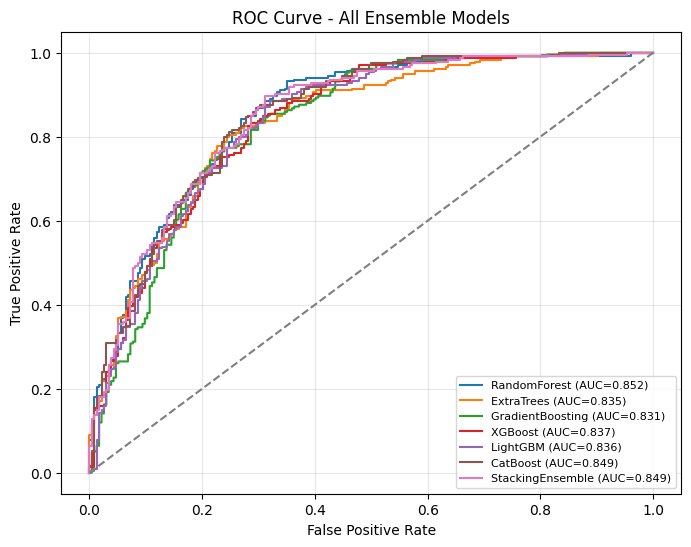

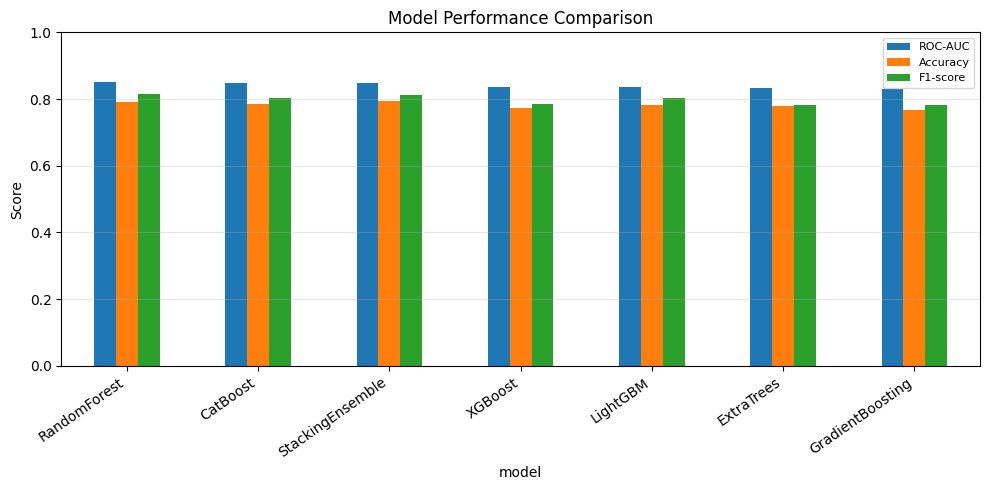

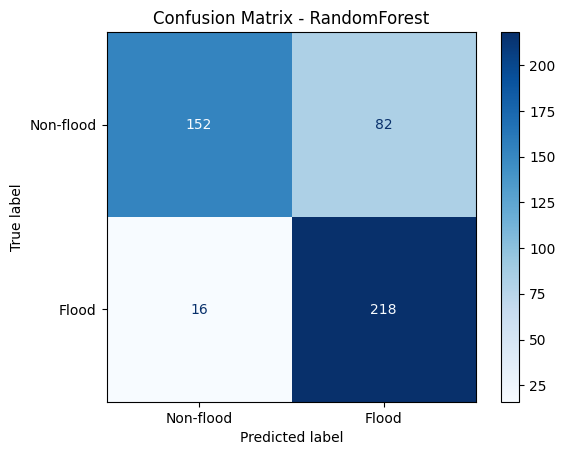

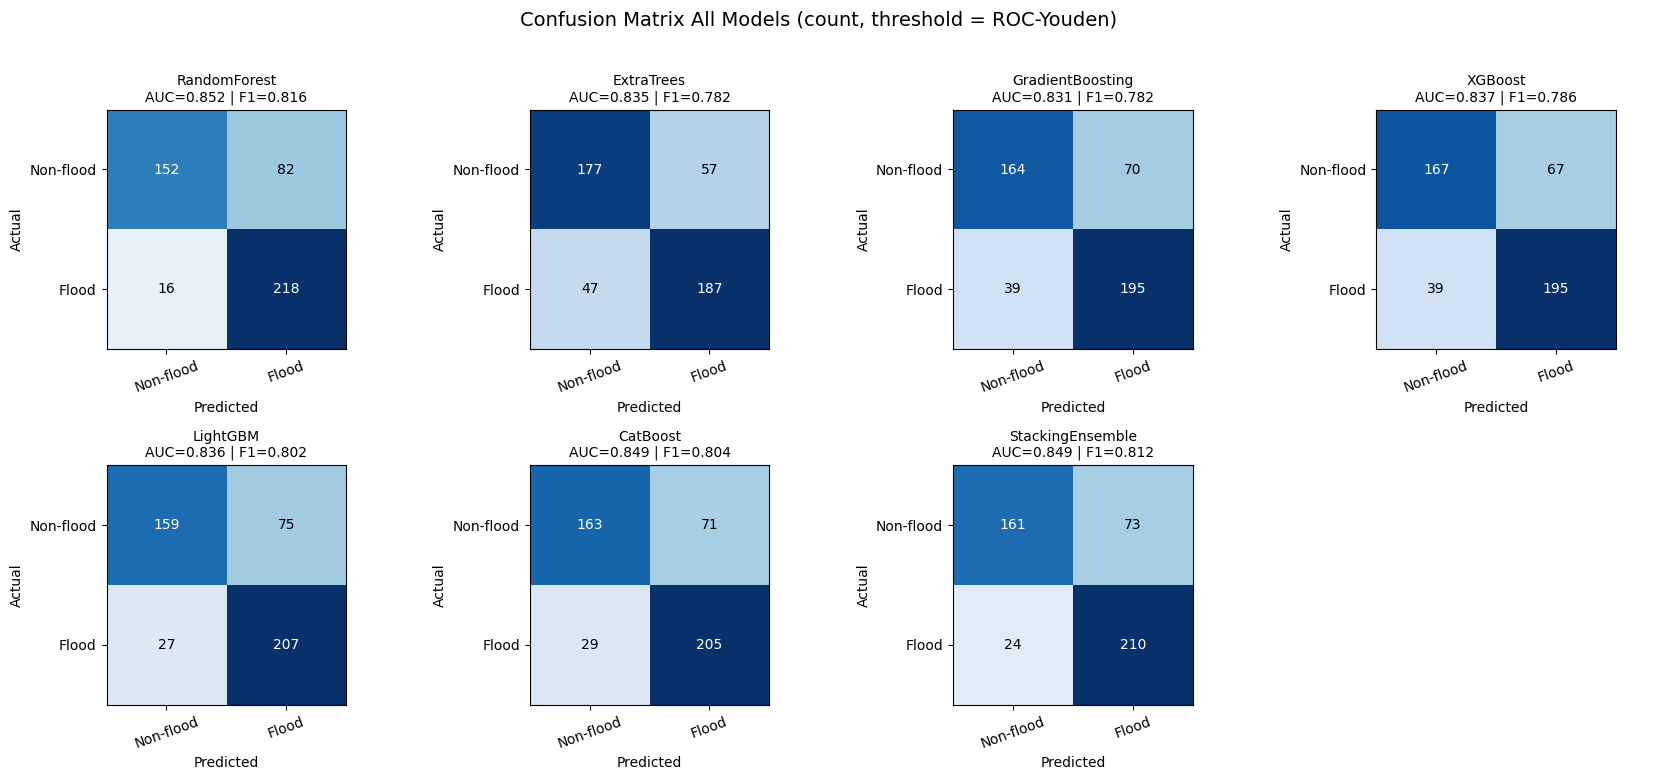

Saved: /content/drive/MyDrive/GEE_Flood_Susceptibility_Semarang_Demak/Python_Outputs_Jeddah_Standard/confusion_matrices_all_models.pdf


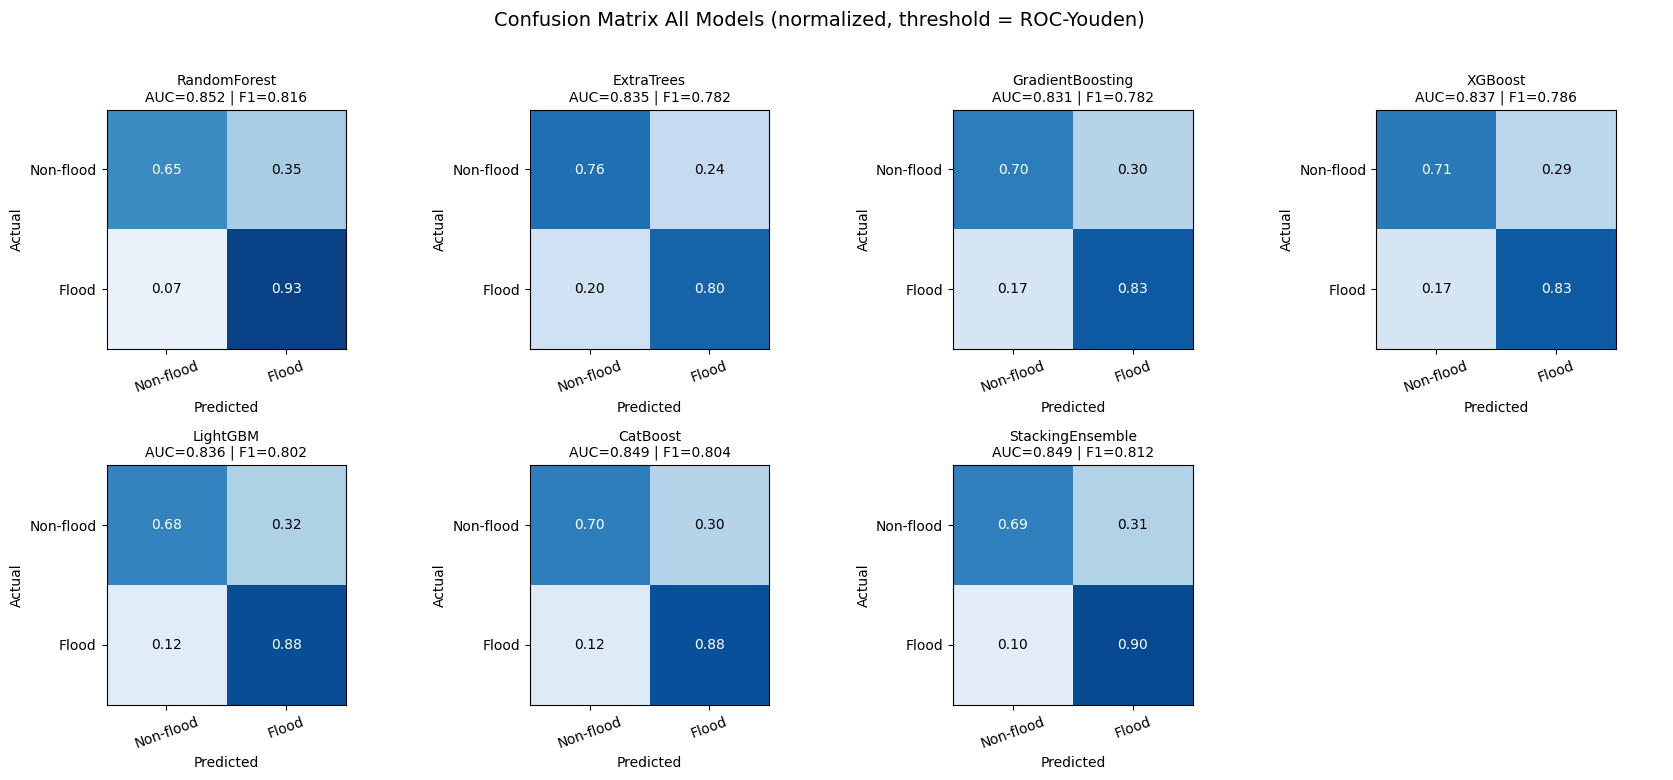

Saved: /content/drive/MyDrive/GEE_Flood_Susceptibility_Semarang_Demak/Python_Outputs_Jeddah_Standard/confusion_matrices_all_models_normalized.pdf
ROC curve: /content/drive/MyDrive/GEE_Flood_Susceptibility_Semarang_Demak/Python_Outputs_Jeddah_Standard/roc_curve.pdf
Metric barplot: /content/drive/MyDrive/GEE_Flood_Susceptibility_Semarang_Demak/Python_Outputs_Jeddah_Standard/model_metric_barplot.pdf
Best model confusion matrix: /content/drive/MyDrive/GEE_Flood_Susceptibility_Semarang_Demak/Python_Outputs_Jeddah_Standard/confusion_matrix.pdf
All confusion matrices: /content/drive/MyDrive/GEE_Flood_Susceptibility_Semarang_Demak/Python_Outputs_Jeddah_Standard/confusion_matrices_all_models.pdf
All normalized confusion matrices: /content/drive/MyDrive/GEE_Flood_Susceptibility_Semarang_Demak/Python_Outputs_Jeddah_Standard/confusion_matrices_all_models_normalized.pdf


In [ ]:
# =========================================================
# ROC Curve semua model
# =========================================================
plt.figure(figsize=(8, 6))
for r in results:
    plt.plot(r['fpr'], r['tpr'], label=f"{r['model']} (AUC={r['roc_auc']:.3f})")
plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - All Ensemble Models')
plt.legend(fontsize=8)
plt.grid(True, alpha=0.3)
roc_path = os.path.join(OUTPUT_DIR, 'roc_curve.pdf')
plt.savefig(roc_path, dpi=300, bbox_inches='tight')
plt.show()

# =========================================================
# Metric barplot seperti ringkasan performa artikel
# =========================================================
plot_metrics = metrics_df.set_index('model')[['roc_auc', 'accuracy_opt', 'f1_opt']]
ax = plot_metrics.plot(kind='bar', figsize=(10, 5))
ax.set_ylim(0, 1)
ax.set_ylabel('Score')
ax.set_title('Model Performance Comparison')
ax.legend(['ROC-AUC', 'Accuracy', 'F1-score'], fontsize=8)
plt.xticks(rotation=35, ha='right')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
metric_barplot_path = os.path.join(OUTPUT_DIR, 'model_metric_barplot.pdf')
plt.savefig(metric_barplot_path, dpi=300, bbox_inches='tight')
plt.show()

# =========================================================
# Confusion Matrix model terbaik
# =========================================================
cm = confusion_matrix(y_test, best_result['y_pred_opt'])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Non-flood', 'Flood'])
disp.plot(values_format='d', cmap='Blues')
plt.title(f'Confusion Matrix - {best_model_name}')
cm_path = os.path.join(OUTPUT_DIR, 'confusion_matrix.pdf')
plt.savefig(cm_path, dpi=300, bbox_inches='tight')
plt.show()

# =========================================================
# Confusion Matrix untuk semua model - count dan normalized
# =========================================================
def plot_all_confusion_matrices(results, y_true, normalize=False, filename='confusion_matrices_all_models.pdf'):
    n_models = len(results)
    n_cols = 4
    n_rows = math.ceil(n_models / n_cols)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.3*n_cols, 3.8*n_rows))
    axes = np.array(axes).reshape(-1)

    for ax, r in zip(axes, results):
        cm = confusion_matrix(y_true, r['y_pred_opt'])
        if normalize:
            cm_plot = cm.astype(float) / cm.sum(axis=1, keepdims=True)
            fmt = '.2f'
            title_suffix = 'normalized'
        else:
            cm_plot = cm
            fmt = 'd'
            title_suffix = 'count'

        ax.imshow(cm_plot, cmap='Blues', vmin=0, vmax=1 if normalize else None)
        ax.set_title(f"{r['model']}\nAUC={r['roc_auc']:.3f} | F1={r['f1_opt']:.3f}", fontsize=10)
        ax.set_xlabel('Predicted')
        ax.set_ylabel('Actual')
        ax.set_xticks([0, 1])
        ax.set_yticks([0, 1])
        ax.set_xticklabels(['Non-flood', 'Flood'], rotation=20)
        ax.set_yticklabels(['Non-flood', 'Flood'])

        threshold_for_text = 0.5 if normalize else (cm_plot.max() / 2 if cm_plot.max() > 0 else 0)
        for i in range(cm_plot.shape[0]):
            for j in range(cm_plot.shape[1]):
                value = format(cm_plot[i, j], fmt)
                text_color = 'white' if cm_plot[i, j] > threshold_for_text else 'black'
                ax.text(j, i, value, ha='center', va='center', color=text_color, fontsize=10)

    for ax in axes[len(results):]:
        ax.axis('off')

    fig.suptitle(f'Confusion Matrix All Models ({title_suffix}, threshold = ROC-Youden)', fontsize=14, y=1.02)
    fig.tight_layout()
    out_path = os.path.join(OUTPUT_DIR, filename)
    plt.savefig(out_path, dpi=300, bbox_inches='tight')
    plt.show()
    print('Saved:', out_path)
    return out_path

cm_all_path = plot_all_confusion_matrices(results, y_test, normalize=False, filename='confusion_matrices_all_models.pdf')
cm_all_norm_path = plot_all_confusion_matrices(results, y_test, normalize=True, filename='confusion_matrices_all_models_normalized.pdf')

print('ROC curve:', roc_path)
print('Metric barplot:', metric_barplot_path)
print('Best model confusion matrix:', cm_path)
print('All confusion matrices:', cm_all_path)
print('All normalized confusion matrices:', cm_all_norm_path)


## 17. Feature Importance

<Figure size 800x600 with 0 Axes>

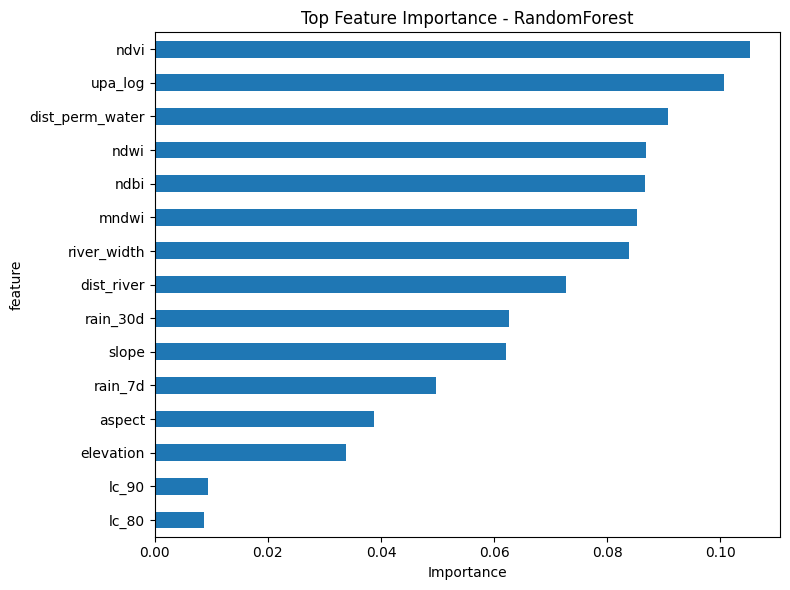

,feature,importance
7,ndvi,0.105305
13,upa_log,0.100742
1,dist_perm_water,0.090836
8,ndwi,0.086878
6,ndbi,0.086685
5,mndwi,0.085349
11,river_width,0.083869
2,dist_river,0.072765
9,rain_30d,0.062716
12,slope,0.062097


In [ ]:
if hasattr(best_model, 'feature_importances_'):
    importance_df = pd.DataFrame({
        'feature': feature_names,
        'importance': best_model.feature_importances_
    }).sort_values('importance', ascending=False)
else:
    perm = permutation_importance(
        best_model, X_test, y_test,
        n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1,
        scoring='roc_auc'
    )
    importance_df = pd.DataFrame({
        'feature': feature_names,
        'importance': perm.importances_mean
    }).sort_values('importance', ascending=False)

importance_path = os.path.join(OUTPUT_DIR, 'feature_importance.csv')
importance_df.to_csv(importance_path, index=False)

plt.figure(figsize=(8, 6))
importance_df.head(15).sort_values('importance').plot(
    x='feature', y='importance', kind='barh', legend=False, figsize=(8, 6)
)
plt.title(f'Top Feature Importance - {best_model_name}')
plt.xlabel('Importance')
plt.tight_layout()
fi_path = os.path.join(OUTPUT_DIR, 'feature_importance.pdf')
plt.savefig(fi_path, dpi=300, bbox_inches='tight')
plt.show()

display(importance_df.head(20))

## 18. SHAP Explainability

Model terbaik: RandomForest
Model untuk SHAP: RandomForest
X_shap shape: (1000, 23)
SHAP shape  : (1000, 23)


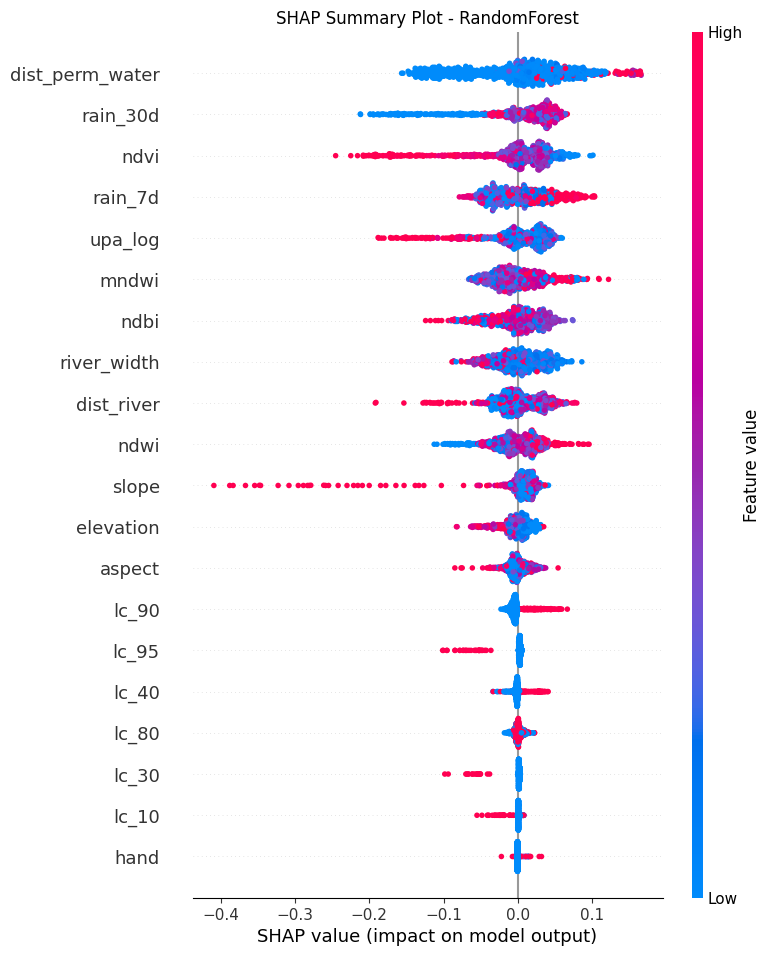

SHAP summary fixed tersimpan: /content/drive/MyDrive/GEE_Flood_Susceptibility_Semarang_Demak/Python_Outputs_Jeddah_Standard/shap_summary_FIXED.pdf


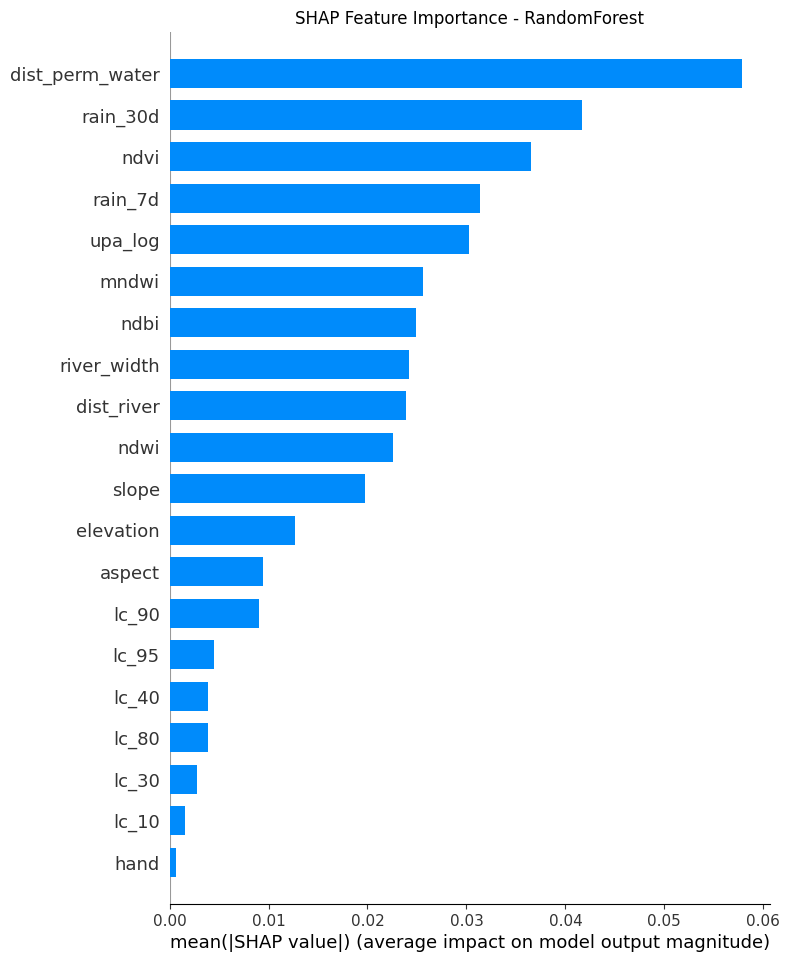

SHAP bar fixed tersimpan: /content/drive/MyDrive/GEE_Flood_Susceptibility_Semarang_Demak/Python_Outputs_Jeddah_Standard/shap_bar_FIXED.pdf
Tabel SHAP importance tersimpan: /content/drive/MyDrive/GEE_Flood_Susceptibility_Semarang_Demak/Python_Outputs_Jeddah_Standard/shap_feature_importance_FIXED.csv


,feature,mean_abs_shap
1,dist_perm_water,0.057801
9,rain_30d,0.041696
7,ndvi,0.036486
10,rain_7d,0.031356
13,upa_log,0.030257
5,mndwi,0.025654
6,ndbi,0.024938
11,river_width,0.024238
2,dist_river,0.023942
8,ndwi,0.022556


In [ ]:
# =========================================================
# SHAP Explainability - fixed untuk binary classification
# =========================================================
if best_model_name == 'StackingEnsemble':
    shap_model_name = 'XGBoost'
    shap_model = fitted_models[shap_model_name]
else:
    shap_model_name = best_model_name
    shap_model = best_model

print('Model terbaik:', best_model_name)
print('Model untuk SHAP:', shap_model_name)

X_shap = X_train.sample(min(1000, len(X_train)), random_state=RANDOM_STATE)

explainer = shap.TreeExplainer(shap_model)
shap_values = explainer.shap_values(X_shap)

# SHAP untuk kelas banjir = 1.
if isinstance(shap_values, list):
    shap_values_to_plot = shap_values[1]
elif hasattr(shap_values, 'ndim') and shap_values.ndim == 3:
    if shap_values.shape[2] == 2:
        shap_values_to_plot = shap_values[:, :, 1]
    elif shap_values.shape[0] == 2:
        shap_values_to_plot = shap_values[1, :, :]
    else:
        raise ValueError(f'Bentuk SHAP 3D tidak dikenali: {shap_values.shape}')
else:
    shap_values_to_plot = shap_values

shap_values_to_plot = np.array(shap_values_to_plot)

print('X_shap shape:', X_shap.shape)
print('SHAP shape  :', shap_values_to_plot.shape)

if shap_values_to_plot.shape[1] != X_shap.shape[1]:
    raise ValueError(
        f'Jumlah fitur SHAP ({shap_values_to_plot.shape[1]}) '
        f'tidak sama dengan jumlah fitur X_shap ({X_shap.shape[1]}).'
    )

# SHAP summary beeswarm.
plt.figure()
shap.summary_plot(
    shap_values_to_plot,
    X_shap,
    max_display=min(20, X_shap.shape[1]),
    show=False
)
plt.title(f'SHAP Summary Plot - {shap_model_name}')
shap_path = os.path.join(OUTPUT_DIR, 'shap_summary_FIXED.pdf')
plt.savefig(shap_path, dpi=300, bbox_inches='tight')
plt.show()
print('SHAP summary fixed tersimpan:', shap_path)

# SHAP bar plot.
plt.figure()
shap.summary_plot(
    shap_values_to_plot,
    X_shap,
    plot_type='bar',
    max_display=min(20, X_shap.shape[1]),
    show=False
)
plt.title(f'SHAP Feature Importance - {shap_model_name}')
shap_bar_path = os.path.join(OUTPUT_DIR, 'shap_bar_FIXED.pdf')
plt.savefig(shap_bar_path, dpi=300, bbox_inches='tight')
plt.show()
print('SHAP bar fixed tersimpan:', shap_bar_path)

# Tabel mean absolute SHAP.
shap_importance_df = pd.DataFrame({
    'feature': X_shap.columns,
    'mean_abs_shap': np.abs(shap_values_to_plot).mean(axis=0)
}).sort_values('mean_abs_shap', ascending=False)

shap_importance_path = os.path.join(OUTPUT_DIR, 'shap_feature_importance_FIXED.csv')
shap_importance_df.to_csv(shap_importance_path, index=False)
print('Tabel SHAP importance tersimpan:', shap_importance_path)
display(shap_importance_df.head(20))


## 19. Simpan model terbaik

In [ ]:
model_path = os.path.join(OUTPUT_DIR, f'best_model_{best_model_name}.joblib')
joblib.dump({
    'model': best_model,
    'feature_names': feature_names,
    'best_threshold_youden': best_threshold,
    'metrics': metrics_df
}, model_path)

print('Model tersimpan di:', model_path)

Model tersimpan di: /content/drive/MyDrive/GEE_Flood_Susceptibility_Semarang_Demak/Python_Outputs_Jeddah_Standard/best_model_RandomForest.joblib


## 20. Peta probabilitas kerawanan banjir di Earth Engine

Model Python seperti XGBoost, LightGBM, CatBoost, dan Stacking tidak langsung diterapkan ke raster GEE. Untuk peta raster praktis, bagian ini melatih Random Forest di Earth Engine dengan sampel yang sama.

Output:
- `prob_map`: probabilitas/kerawanan banjir 0–1.
- `risk_class`: kelas kerawanan 1–5.

Probabilitas tinggi berarti area tersebut mirip dengan area historis yang terdeteksi tergenang. Ini bukan prediksi banjir real-time. Untuk artikel, tulis eksplisit bahwa model terbaik hasil evaluasi Python dan model operasional raster GEE merupakan dua tahap yang berbeda.


In [ ]:
# =========================================================
# 21. Random Forest GEE untuk peta probabilitas
# =========================================================

gee_predictor_bands = predictor_bands

# RF GEE memakai sample_fc yang sudah diseimbangkan pada Cell 9.
gee_rf = (ee.Classifier.smileRandomForest(
            numberOfTrees=300,
            variablesPerSplit=None,
            minLeafPopulation=2,
            bagFraction=0.7,
            seed=RANDOM_STATE
          )
          .setOutputMode('PROBABILITY')
          .train(
              features=sample_fc,
              classProperty='flood',
              inputProperties=gee_predictor_bands
          ))

prob_map = predictor_stack.select(gee_predictor_bands).classify(gee_rf).rename('flood_susceptibility')

# =========================================================
# Klasifikasi peta kerawanan
# =========================================================
# equal_interval = kelas tetap 0.00-0.20, 0.20-0.40, dst.
# quantile       = kelas berdasarkan distribusi nilai probabilitas di ROI.
# Jika peta equal interval terlalu merah, quantile lebih readable untuk visual artikel.
RISK_CLASS_METHOD = 'quantile'

risk_class_equal_interval = prob_map.expression(
    "(p <= 0.2) ? 1" +
    ": (p <= 0.4) ? 2" +
    ": (p <= 0.6) ? 3" +
    ": (p <= 0.8) ? 4" +
    ": 5",
    {'p': prob_map}
).rename('risk_class')

if RISK_CLASS_METHOD == 'quantile':
    try:
        prob_percentiles = prob_map.reduceRegion(
            reducer=ee.Reducer.percentile([20, 40, 60, 80]),
            geometry=roi,
            scale=30,
            maxPixels=1e13,
            tileScale=TILE_SCALE
        ).getInfo()

        p20_value = prob_percentiles.get('flood_susceptibility_p20')
        p40_value = prob_percentiles.get('flood_susceptibility_p40')
        p60_value = prob_percentiles.get('flood_susceptibility_p60')
        p80_value = prob_percentiles.get('flood_susceptibility_p80')

        if None in [p20_value, p40_value, p60_value, p80_value]:
            raise ValueError(f'Percentile tidak lengkap: {prob_percentiles}')

        print('Quantile threshold probability:')
        print('p20:', p20_value)
        print('p40:', p40_value)
        print('p60:', p60_value)
        print('p80:', p80_value)

        risk_class = prob_map.expression(
            "(p <= p20) ? 1" +
            ": (p <= p40) ? 2" +
            ": (p <= p60) ? 3" +
            ": (p <= p80) ? 4" +
            ": 5",
            {
                'p': prob_map,
                'p20': ee.Number(p20_value),
                'p40': ee.Number(p40_value),
                'p60': ee.Number(p60_value),
                'p80': ee.Number(p80_value)
            }
        ).rename('risk_class')

    except Exception as e:
        print('Klasifikasi quantile gagal. Fallback ke equal interval.', e)
        RISK_CLASS_METHOD = 'equal_interval'
        risk_class = risk_class_equal_interval

elif RISK_CLASS_METHOD == 'equal_interval':
    risk_class = risk_class_equal_interval

else:
    raise ValueError("RISK_CLASS_METHOD harus 'equal_interval' atau 'quantile'.")

print('Peta probabilitas dan kelas kerawanan selesai dibuat.')
print('Metode klasifikasi risk_class:', RISK_CLASS_METHOD)


Quantile threshold probability:
p20: 0.17393989523770684
p40: 0.29483152836958665
p60: 0.45538451939465957
p80: 0.6384894690854527
Peta probabilitas dan kelas kerawanan selesai dibuat.
Metode klasifikasi risk_class: quantile


In [ ]:
# =========================================================
# REPRODUCIBILITY: simpan threshold kuantil klasifikasi peta ke CSV.
# =========================================================
try:
    _rows = [{'method': RISK_CLASS_METHOD,
              'p20': p20_value, 'p40': p40_value,
              'p60': p60_value, 'p80': p80_value}]
except NameError:
    _rows = [{'method': RISK_CLASS_METHOD,
              'p20': 0.2, 'p40': 0.4, 'p60': 0.6, 'p80': 0.8}]
pd.DataFrame(_rows).to_csv(
    os.path.join(OUTPUT_DIR, 'susceptibility_class_thresholds.csv'), index=False)
print('Tersimpan: susceptibility_class_thresholds.csv')

## 21. Visualisasi peta probabilitas dan kelas kerawanan

Peta ini dibuat menggunakan Random Forest di Google Earth Engine sebagai model operasional raster. Hasil evaluasi sampel tetap menggunakan semua model Python, sedangkan peta raster memakai model GEE agar langsung dapat diterapkan ke seluruh piksel wilayah studi.

Layer utama:
- probabilitas kerawanan 0-1,
- kelas kerawanan 1-5,
- proxy flood label Sentinel-1,
- ROI.


In [ ]:
Map3 = geemap.Map()
Map3.add_basemap('HYBRID')
center_map_on_roi(Map3, roi, MAP_ZOOM)
Map3.addLayer(roi, {'color': 'black'}, 'ROI Semarang-Demak')
Map3.addLayer(prob_map, PROB_VIS, 'Flood susceptibility probability - RF GEE')
Map3.addLayer(risk_class, RISK_VIS, f'Classified susceptibility 1-5 - {RISK_CLASS_METHOD}')
Map3.addLayer(flood_label.selfMask(), {'palette': ['#ff00ff']}, 'Proxy flood label')
safe_add_legend(Map3, 'Susceptibility class', risk_legend)
safe_add_legend(Map3, 'Flood label', {'Proxy flood label': '#ff00ff'})
safe_add_layer_control(Map3)
map_final_html = save_map_html(Map3, f'map_03_final_susceptibility_{RISK_CLASS_METHOD}.html')
Map3


Map HTML tersimpan: /content/drive/MyDrive/GEE_Flood_Susceptibility_Semarang_Demak/Python_Outputs_Jeddah_Standard/map_03_final_susceptibility_quantile.html


Map(center=[-6.9475803324210075, 110.56793539002611], controls=(WidgetControl(options=['position', 'transparen…

## 21b. Figure statis

- figure label dan prediktor,
- figure final peta kerawanan,
- figure peta prediktor terpilih.


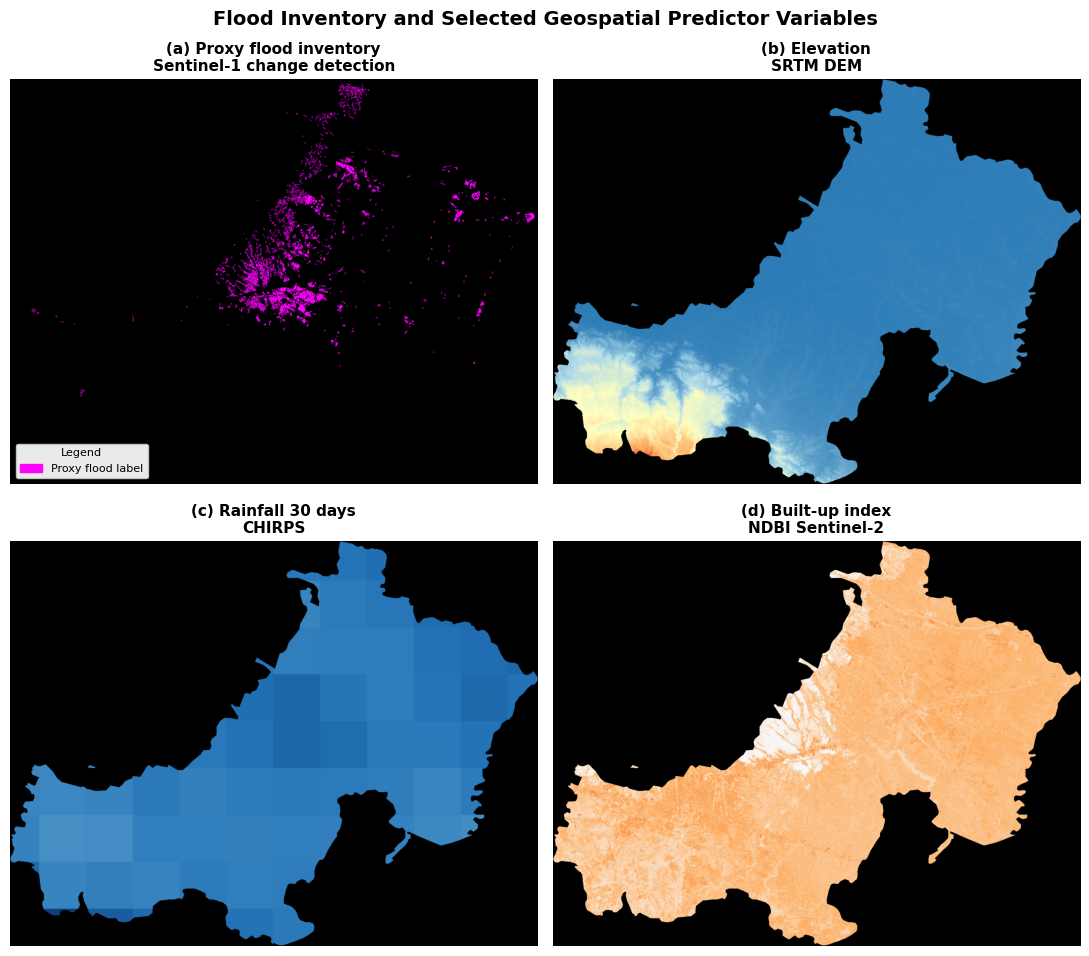

Figure label dan prediktor tersimpan: /content/drive/MyDrive/GEE_Flood_Susceptibility_Semarang_Demak/Python_Outputs_Jeddah_Standard/figure_01_label_and_predictors.pdf


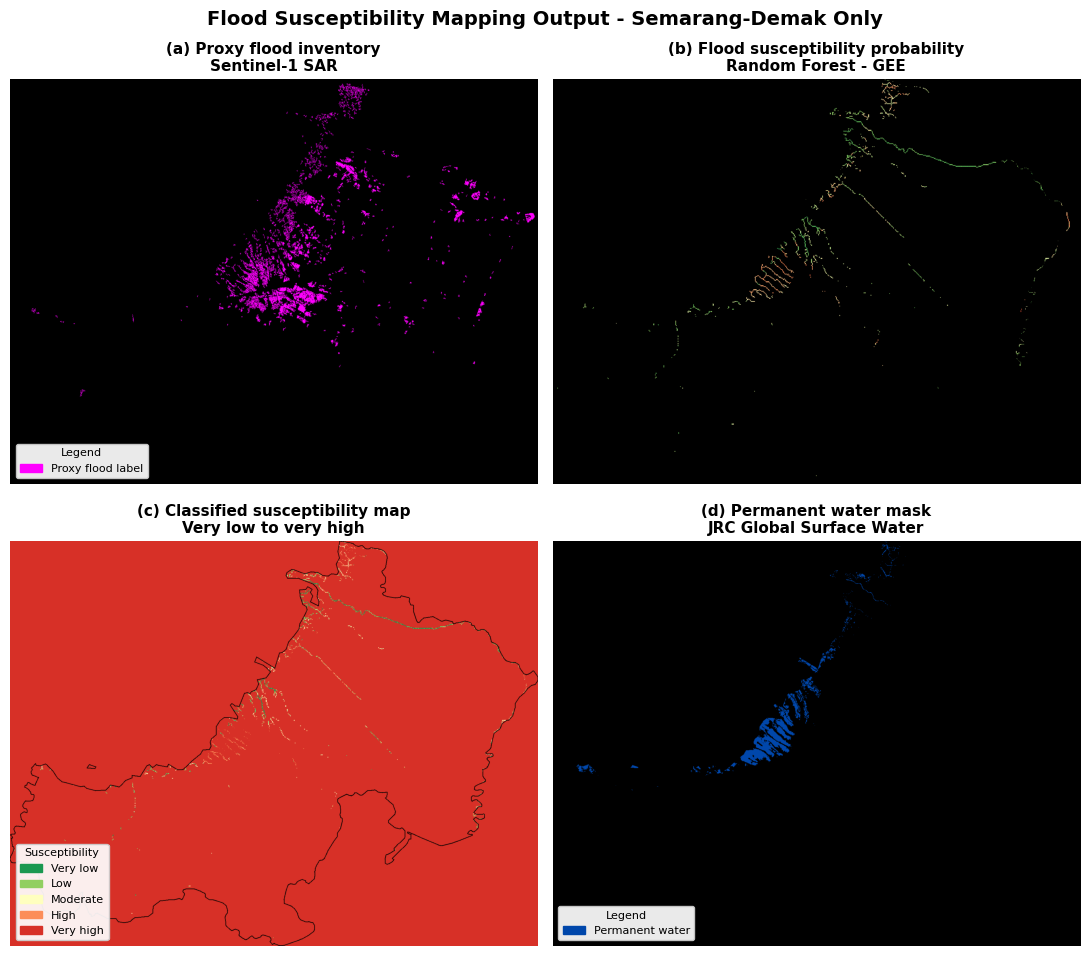

Figure final peta kerawanan tersimpan: /content/drive/MyDrive/GEE_Flood_Susceptibility_Semarang_Demak/Python_Outputs_Jeddah_Standard/figure_02_final_flood_susceptibility_map.pdf


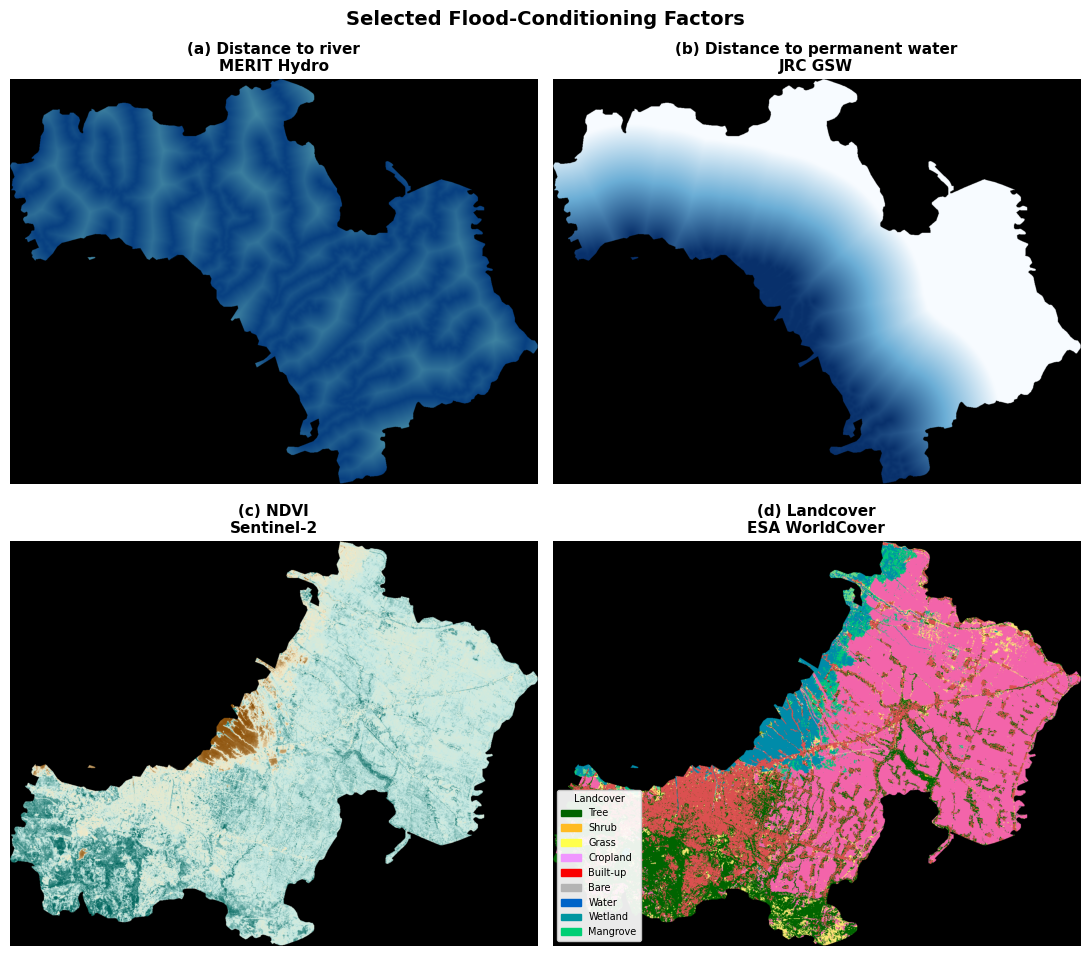

Figure faktor pengondisi banjir tersimpan: /content/drive/MyDrive/GEE_Flood_Susceptibility_Semarang_Demak/Python_Outputs_Jeddah_Standard/figure_03_flood_conditioning_factors.pdf


In [ ]:
# =========================================================
# Figure 1: label banjir dan prediktor utama
# =========================================================
try:
    fig1_panels = [
        ('(a) Proxy flood inventory\nSentinel-1 change detection', flood_label.selfMask(), FLOOD_VIS, 'flood'),
        ('(b) Elevation\nSRTM DEM', dem, ELEVATION_VIS, 'continuous'),
        ('(c) Rainfall 30 days\nCHIRPS', rain_30d, RAIN_VIS, 'continuous'),
        ('(d) Built-up index\nNDBI Sentinel-2', ndbi, NDBI_VIS, 'continuous')
    ]

    fig, axes = plt.subplots(2, 2, figsize=(11, 10))
    axes = axes.ravel()

    for ax, (title, img, vis, kind) in zip(axes, fig1_panels):
        thumb = ee_thumb(img, vis, roi, dimensions=1600)
        ax.imshow(thumb)
        ax.set_title(title, fontsize=11, fontweight='bold')
        ax.axis('off')
        if kind == 'flood':
            add_discrete_legend(ax, ['Proxy flood label'], ['#ff00ff'], title='Legend')

    fig.suptitle('Flood Inventory and Selected Geospatial Predictor Variables', fontsize=14, fontweight='bold')
    fig.tight_layout()
    predictor_figure_path = os.path.join(OUTPUT_DIR, 'figure_01_label_and_predictors.pdf')
    plt.savefig(predictor_figure_path, dpi=300, bbox_inches='tight')
    plt.show()
    print('Figure label dan prediktor tersimpan:', predictor_figure_path)
except Exception as e:
    print('Gagal membuat figure label/prediktor:', e)

# =========================================================
# Figure 2: output akhir peta kerawanan banjir
# =========================================================
try:
    fig2_panels = [
        ('(a) Proxy flood inventory\nSentinel-1 SAR', flood_label.selfMask(), FLOOD_VIS, 'flood'),
        ('(b) Flood susceptibility probability\nRandom Forest - GEE', prob_map, PROB_VIS, 'prob'),
        ('(c) Classified susceptibility map\nVery low to very high', risk_class, RISK_VIS, 'risk'),
        ('(d) Permanent water mask\nJRC Global Surface Water', permanent_water.selfMask(), PERM_WATER_VIS, 'water')
    ]

    fig, axes = plt.subplots(2, 2, figsize=(11, 10))
    axes = axes.ravel()

    for ax, (title, img, vis, kind) in zip(axes, fig2_panels):
        thumb = ee_thumb(img, vis, roi, dimensions=1600)
        ax.imshow(thumb)
        ax.set_title(title, fontsize=11, fontweight='bold')
        ax.axis('off')
        if kind == 'risk':
            add_discrete_legend(
                ax,
                ['Very low', 'Low', 'Moderate', 'High', 'Very high'],
                ['#1a9850', '#91cf60', '#ffffbf', '#f16913', '#7f0000'],
                title='Susceptibility'
            )
        elif kind == 'flood':
            add_discrete_legend(ax, ['Proxy flood label'], ['#ff00ff'], title='Legend')
        elif kind == 'water':
            add_discrete_legend(ax, ['Permanent water'], ['#0047ab'], title='Legend')

    fig.suptitle('Flood Susceptibility Mapping Output - Semarang-Demak Only', fontsize=14, fontweight='bold')
    fig.tight_layout()
    final_figure_path = os.path.join(OUTPUT_DIR, 'figure_02_final_flood_susceptibility_map.pdf')
    plt.savefig(final_figure_path, dpi=300, bbox_inches='tight')
    plt.show()
    print('Figure final peta kerawanan tersimpan:', final_figure_path)
except Exception as e:
    print('Gagal membuat figure final peta kerawanan:', e)

# =========================================================
# Figure 3: flood conditioning factors panel
# =========================================================
try:
    fig3_panels = [
        ('(a) Distance to river\nMERIT Hydro', dist_river, {'min': 0, 'max': 10000, 'palette': ['#084081', '#7bccc4', '#ffffcc']}, 'continuous'),
        ('(b) Distance to permanent water\nJRC GSW', dist_perm_water, {'min': 0, 'max': 10000, 'palette': ['#08306b', '#6baed6', '#f7fbff']}, 'continuous'),
        ('(c) NDVI\nSentinel-2', ndvi, NDVI_VIS, 'continuous'),
        ('(d) Landcover\nESA WorldCover', landcover, {'min': 10, 'max': 100, 'palette': ['006400','ffbb22','ffff4c','f096ff','fa0000','b4b4b4','f0f0f0','0064c8','0096a0','00cf75','fae6a0']}, 'landcover')
    ]

    fig, axes = plt.subplots(2, 2, figsize=(11, 10))
    axes = axes.ravel()

    for ax, (title, img, vis, kind) in zip(axes, fig3_panels):
        thumb = ee_thumb(img, vis, roi, dimensions=1600)
        ax.imshow(thumb)
        ax.set_title(title, fontsize=11, fontweight='bold')
        ax.axis('off')
        if kind == 'landcover':
            add_discrete_legend(
                ax,
                ['Tree', 'Shrub', 'Grass', 'Cropland', 'Built-up', 'Bare', 'Water', 'Wetland', 'Mangrove'],
                ['#006400', '#ffbb22', '#ffff4c', '#f096ff', '#fa0000', '#b4b4b4', '#0064c8', '#0096a0', '#00cf75'],
                title='Landcover', fontsize=7
            )

    fig.suptitle('Selected Flood-Conditioning Factors', fontsize=14, fontweight='bold')
    fig.tight_layout()
    factors_figure_path = os.path.join(OUTPUT_DIR, 'figure_03_flood_conditioning_factors.pdf')
    plt.savefig(factors_figure_path, dpi=300, bbox_inches='tight')
    plt.show()
    print('Figure faktor pengondisi banjir tersimpan:', factors_figure_path)
except Exception as e:
    print('Gagal membuat figure faktor pengondisi:', e)


## 22. Export peta dan data ke Google Drive

In [ ]:
# Ubah EXPORT_TO_DRIVE menjadi True jika ingin ekspor GeoTIFF dan CSV.

EXPORT_TO_DRIVE = True
DRIVE_FOLDER = 'GEE_Flood_Susceptibility_Semarang_Demak'

if EXPORT_TO_DRIVE:
    # Export peta probabilitas kerawanan banjir
    task_prob = ee.batch.Export.image.toDrive(
        image=prob_map.toFloat(),
        description='semarang_demak_flood_susceptibility_probability',
        folder=DRIVE_FOLDER,
        fileNamePrefix='semarang_demak_flood_susceptibility_probability',
        region=roi,
        scale=30,
        maxPixels=1e13
    )
    task_prob.start()
    print('Export probability map started:', task_prob.status())

    # Export peta kelas kerawanan 1-5
    task_class = ee.batch.Export.image.toDrive(
        image=risk_class.toByte(),
        description='semarang_demak_flood_susceptibility_risk_class',
        folder=DRIVE_FOLDER,
        fileNamePrefix='semarang_demak_flood_susceptibility_risk_class',
        region=roi,
        scale=30,
        maxPixels=1e13
    )
    task_class.start()
    print('Export risk class map started:', task_class.status())

    # Export label banjir hasil Sentinel-1
    task_label = ee.batch.Export.image.toDrive(
        image=flood_label.toByte(),
        description='semarang_demak_proxy_flood_label_sentinel1',
        folder=DRIVE_FOLDER,
        fileNamePrefix='semarang_demak_proxy_flood_label_sentinel1',
        region=roi,
        scale=30,
        maxPixels=1e13
    )
    task_label.start()
    print('Export proxy flood label started:', task_label.status())

    # Export sampel training sebagai CSV
    task_table = ee.batch.Export.table.toDrive(
        collection=sample_fc,
        description='semarang_demak_training_sample',
        folder=DRIVE_FOLDER,
        fileNamePrefix='semarang_demak_training_sample',
        fileFormat='CSV'
    )
    task_table.start()
    print('Export training sample started:', task_table.status())
else:
    print('EXPORT_TO_DRIVE = False. Ubah menjadi True jika ingin export ke Google Drive.')

Export probability map started: {'state': 'READY', 'description': 'semarang_demak_flood_susceptibility_probability', 'priority': 100, 'creation_timestamp_ms': 1786032917529, 'update_timestamp_ms': 1786032917529, 'start_timestamp_ms': 0, 'task_type': 'EXPORT_IMAGE', 'id': 'LFUKAMPDPWM3YBJWEY7EVNER', 'name': 'projects/ee-irfan-banjir-2026/operations/LFUKAMPDPWM3YBJWEY7EVNER'}
Export risk class map started: {'state': 'READY', 'description': 'semarang_demak_flood_susceptibility_risk_class', 'priority': 100, 'creation_timestamp_ms': 1786032918324, 'update_timestamp_ms': 1786032918324, 'start_timestamp_ms': 0, 'task_type': 'EXPORT_IMAGE', 'id': '6XIWNMFBZ37G7U7BGEVVNXWN', 'name': 'projects/ee-irfan-banjir-2026/operations/6XIWNMFBZ37G7U7BGEVVNXWN'}
Export proxy flood label started: {'state': 'READY', 'description': 'semarang_demak_proxy_flood_label_sentinel1', 'priority': 100, 'creation_timestamp_ms': 1786032919203, 'update_timestamp_ms': 1786032919203, 'start_timestamp_ms': 0, 'task_type': '

## 23. Uji sensitivitas threshold label Sentinel-1

In [ ]:
# =========================================================
# Uji sensitivitas threshold Sentinel-1
# =========================================================

thresholds_to_test = [1.15, 1.25, 1.35, 1.50]
area_results = []

pixel_area = ee.Image.pixelArea()

for th in thresholds_to_test:
    flood_tmp = (s1_ratio.gt(th)
                 .And(after_pol_db.lt(AFTER_DB_THRESHOLD))
                 .And(permanent_water.Not())
                 .And(slope.lt(SLOPE_MAX_FOR_FLOOD)))
    flood_tmp = (flood_tmp.selfMask()
                 .connectedPixelCount(100, True)
                 .gte(MIN_CONNECTED_PIXELS)
                 .unmask(0))

    area_m2 = (pixel_area.updateMask(flood_tmp)
               .reduceRegion(
                   reducer=ee.Reducer.sum(),
                   geometry=roi,
                   scale=30,
                   maxPixels=1e13,
                   tileScale=TILE_SCALE
               )
               .get('area'))

    area_km2 = ee.Number(area_m2).divide(1e6).getInfo()
    area_results.append({'s1_ratio_threshold': th, 'estimated_flood_area_km2': area_km2})

sensitivity_df = pd.DataFrame(area_results)
sensitivity_path = os.path.join(OUTPUT_DIR, 's1_threshold_sensitivity.csv')
sensitivity_df.to_csv(sensitivity_path, index=False)

display(sensitivity_df)

,s1_ratio_threshold,estimated_flood_area_km2
0,1.15,56.109571
1,1.25,51.996175
2,1.35,48.511744
3,1.50,44.065502


## 24. Metodologi Utama

Label target banjir dibentuk dari *flood inventory* berbasis citra Sentinel-1 SAR. Citra sebelum dan sesudah kejadian banjir dibandingkan menggunakan pendekatan *change detection* pada nilai backscatter. Area yang mengalami perubahan signifikan dan tidak termasuk air permanen diklasifikasikan sebagai indikasi genangan banjir. Data kejadian dari BNPB/BPBD/berita digunakan untuk menentukan periode kejadian dan memperkuat justifikasi pemilihan tanggal citra.

Model yang digunakan adalah supervised classification dengan label 1 untuk area terindikasi banjir dan label 0 untuk area tidak terindikasi banjir. Variabel prediktor diperoleh dari data geospasial multi-sumber yang meliputi faktor topografi, hidrologi, curah hujan, tutupan lahan, dan indeks spektral. Output model berupa probabilitas kerawanan banjir, bukan status banjir aktual pada tanggal tertentu. Probabilitas tersebut kemudian diklasifikasikan menjadi lima kelas kerawanan, yaitu sangat rendah, rendah, sedang, tinggi, dan sangat tinggi.

Evaluasi dilakukan dengan membandingkan beberapa model ensemble learning, yaitu Random Forest, ExtraTrees, Gradient Boosting, XGBoost, LightGBM, CatBoost, dan Stacking Ensemble. Confusion matrix dibuat untuk seluruh model agar performa masing-masing model dapat dibandingkan secara visual. Interpretasi faktor pengondisi banjir dilakukan menggunakan SHAP pada model terbaik atau model interpretasi pendukung.

Untuk pemetaan raster, Random Forest di Google Earth Engine digunakan sebagai model operasional karena dapat langsung diterapkan pada citra prediktor spasial. Dengan demikian, hasil evaluasi model pada data sampel dan hasil pemetaan raster perlu dibedakan secara eksplisit dalam artikel.

Pada versi Semarang-Demak only, sampling dibuat otomatis dan seimbang. Jika piksel banjir yang tersedia hanya sekitar 1630, maka jumlah sampel non-banjir juga dibatasi menjadi 1630 agar model tidak bias karena imbalance.


## 25. Batasan penelitian

1. Label banjir berasal dari deteksi Sentinel-1, sehingga merupakan *proxy label*, bukan validasi lapangan langsung.
2. Deteksi banjir SAR dapat terganggu pada area urban padat, vegetasi rapat, tambak, sawah tergenang, dan air permanen.
3. Threshold Sentinel-1 perlu diuji sensitivitasnya.
4. Probabilitas model harus diinterpretasikan sebagai kerawanan/susceptibility, bukan prediksi banjir real-time.
5. Untuk mengurangi *data leakage*, indeks Sentinel-2 dihitung dari periode normal atau pra-kejadian, bukan dari periode saat banjir.
6. Jika ROI dibatasi hanya Kota Semarang dan Kabupaten Demak, jumlah piksel banjir yang tersedia lebih sedikit daripada ROI rectangle Semarang-Demak dan sekitarnya. Karena itu ukuran sampel menjadi lebih kecil, tetapi lebih sesuai dengan batas studi kasus.
7. Model terbaik Python dan model peta GEE dapat berbeda fungsi. Model Python digunakan untuk evaluasi komparatif, sedangkan Random Forest GEE dipakai sebagai implementasi raster operasional.
8. `dist_river` adalah aproksimasi berbasis MERIT Hydro upstream drainage area, sehingga perlu dijelaskan sebagai *derived hydrological predictor*, bukan data jarak sungai survei lapangan.
